# Plotting results — OVCA leave-one-cell-type-out benchmark

Figures for the results of [`OVCA_03_loo_with_baseline.ipynb`](OVCA_03_loo_with_baseline.ipynb).
**Nothing is trained or re-scored here.** The notebook reads that notebook's cached predictions and
metric CSVs in `/scratch/spiljak/wsi_ood_preds/ovca_loo/`. Kernel: `lazyslide-env` (also runs on `cellina_edge`).

**The question, in one line.** All Stromal cells in Tumor are hidden during training. Can a model
predict how Stromal cells' expression changes when they move from Smooth muscle into Tumor? We
compare three ways of telling the model "this cell is in Tumor":

| model | what it is told about the cell's surroundings | kind |
|---|---|---|
| **Labels** | a one-hot *domain* label (Tumor) | counterfactual |
| **Virchow2 / UNI2 emb, donor** | the H&E tile embedding of a real Tumor cell (the *donor*: it lends only its image vector, never its expression). Donor pool = Tumor cells in the other 8 ROIs ("generic tumour") or in the held-out ROIs 3/6/8/9 ("this niche") | counterfactual |
| **Virchow2 / UNI2 emb, own tile** | the real Stromal cell's own tile, which the model reads directly | direct, **ceiling** |
| **Path2Space** | nothing: pixels in, expression out. External model trained on breast cancer Visium | direct, **baseline** |

*Counterfactual* = the prediction starts from a Smooth-muscle cell and swaps only its context
input. *Direct* = the prediction is made from the target cell's own image, which is an easier task.
Filled markers are counterfactual models and hollow markers are direct models throughout.

**Regimes.** *OOD* = the held-out cell type (Stromal, 2,538 predicted vs 560 observed cells). This
is the main result. *ID* = the held-in types (Endothelial, Malignant, Myeloid), scored **within
each cell type** and then averaged (Table C3), because the pooled ID compares different cell
mixtures.

All figures use the **3,603 genes shared with Path2Space** (Table C2/C3 gene universe). Figures
are saved as PNG + PDF to `figures/plotting_results/`.

## 0. Setup

In [1]:
import os, sys
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde, pearsonr

PROJECT_ROOT = "/g/stegle/spiljak/projects/main_wsi_ood"
sys.path.append(os.path.join(PROJECT_ROOT, "scripts"))
from metrics import get_perturbation_effects

PRED_DIR = "/scratch/spiljak/wsi_ood_preds/ovca_loo"
FIG_DIR = os.path.join(PROJECT_ROOT, "notebooks/figures/plotting_results")
os.makedirs(FIG_DIR, exist_ok=True)

PERT_COL, LABELS_KEY = "domain_arm", "cell_type"
CONTROL_LABEL, HOLDOUT_LABEL, HOLDOUT_CT = "Smooth muscle", "Tumor", "Stromal"
SEEDS = [0, 1, 2]
GENE_SEED = 0      # seed shown in the gene-level plots (scatter, Bland-Altman, top-50 heatmap)
TOP_N = 50         # the benchmark's top-DE-gene cutoff

# key -> (display name in the metric CSVs, kind, seeds). Same registry as the benchmark notebook.
MODELS = {
    "labels":               ("labels",                             "counterfactual",    SEEDS),
    "emb_seen_8ROIs":       ("Virchow2 emb (donor: other 8 ROIs)", "counterfactual",    SEEDS),
    "emb_unseen_ROIs":      ("Virchow2 emb (donor: ROIs 3/6/8/9)", "counterfactual",    SEEDS),
    "emb_ceiling":          ("Virchow2 emb (own tile)",            "direct - CEILING",  SEEDS),
    "uni2_emb_seen_8ROIs":  ("UNI2 emb (donor: other 8 ROIs)",     "counterfactual",    SEEDS),
    "uni2_emb_unseen_ROIs": ("UNI2 emb (donor: ROIs 3/6/8/9)",     "counterfactual",    SEEDS),
    "uni2_emb_ceiling":     ("UNI2 emb (own tile)",                "direct - CEILING",  SEEDS),
    "path2space":           ("Path2Space (CTransPath, own tile)",  "direct - BASELINE", None),
}
# Short plot labels.
SHORT = {
    "labels":               "Labels",
    "emb_seen_8ROIs":       "Virchow2 · donor, other ROIs",
    "emb_unseen_ROIs":      "Virchow2 · donor, same ROIs",
    "emb_ceiling":          "Virchow2 · own tile",
    "uni2_emb_seen_8ROIs":  "UNI2 · donor, other ROIs",
    "uni2_emb_unseen_ROIs": "UNI2 · donor, same ROIs",
    "uni2_emb_ceiling":     "UNI2 · own tile",
    "path2space":           "Path2Space · own tile",
}
DISPLAY2KEY = {v[0]: k for k, v in MODELS.items()}

# Colour = model family (fixed order, validated categorical slots 1-3 + neutral for the baseline).
FAMILY = lambda k: ("labels" if k == "labels" else "uni2" if k.startswith("uni2")
                    else "path2space" if k == "path2space" else "virchow2")
FAMILY_COLOR = {"labels": "#2a78d6", "virchow2": "#eb6834", "uni2": "#1baf7a", "path2space": "#52514e"}
FAMILY_NAME = {"labels": "Labels", "virchow2": "Virchow2 emb", "uni2": "UNI2 emb", "path2space": "Path2Space"}
color = lambda k: FAMILY_COLOR[FAMILY(k)]
is_direct = lambda k: MODELS[k][1].startswith("direct")
MARKER = lambda k: "s" if k == "path2space" else "D" if is_direct(k) else "o"

METRICS = ["pearson_logfc", "rmse_logfc", "spearman_avg", "precision_at_top_n", "edistance_pca"]
METRIC_LABEL = {
    "pearson_logfc": "Pearson r, logFC (top-50)",
    "rmse_logfc": "RMSE, logFC (top-50)",
    "spearman_avg": "Spearman, mean expression",
    "precision_at_top_n": "Precision@50",
    "edistance_pca": "Energy distance (PCA)",
}
HIGHER_BETTER = {"pearson_logfc": True, "rmse_logfc": False, "spearman_avg": True,
                 "precision_at_top_n": True, "edistance_pca": False}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "legend.frameon": False, "pdf.fonttype": 42,
})
GRID = dict(color="#e4e3df", lw=0.6, zorder=0)


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))


# Metrics: C3 per-seed file = OOD rows (copied from C2) + ID scored within cell type.
per_seed = pd.read_csv(os.path.join(PRED_DIR, "metrics_C3_sharedgenes_per_seed.csv"))
per_seed["key"] = per_seed["model"].map(DISPLAY2KEY)
assert per_seed["key"].notna().all()
REGIME_TITLE = {"OOD": "OOD: held-out Stromal cells",
                "ID": "ID: held-in types (per-type mean)"}
per_seed.groupby(["regime", "key"])["pearson_logfc"].agg(["mean", "std", "count"]).round(3)

mean    std  count
regime key                                      
ID     emb_ceiling           0.760  0.022      3
       emb_seen_8ROIs        0.631  0.006      3
       emb_unseen_ROIs       0.677  0.017      3
       labels                0.864  0.005      3
       path2space            0.249    NaN      1
       uni2_emb_ceiling      0.589  0.005      3
       uni2_emb_seen_8ROIs   0.545  0.003      3
       uni2_emb_unseen_ROIs  0.538  0.012      3
OOD    emb_ceiling           0.658  0.069      3
       emb_seen_8ROIs        0.423  0.024      3
       emb_unseen_ROIs       0.524  0.045      3
       labels                0.725  0.054      3
       path2space            0.636    NaN      1
       uni2_emb_ceiling      0.477  0.019      3
       uni2_emb_seen_8ROIs   0.364  0.008      3
       uni2_emb_unseen_ROIs  0.403  0.014      3

### Per-gene logFC for every model and seed (OOD, shared genes)

Same computation as the benchmark's scatter: `get_perturbation_effects` with the
`observed_control` baseline, so observed and predicted logFC are both measured against the **real**
Smooth-muscle Stromal cells, in CPM→1e4→log1p space. Cached to
`PRED_DIR/plotting_ood_logfc_sharedgenes.npz` after the first run (~22 h5ads to read).

In [2]:
def read_h5ad_compat(path):
    """sc.read, falling back to h5py for files written by anndata >= 0.11 (see benchmark nb)."""
    import anndata as ad
    import h5py
    try:
        return sc.read(path)
    except Exception as err:
        if "nullable-string-array" not in str(err):
            raise

    def _strings(g):
        return (g["values"] if isinstance(g, h5py.Group) else g).asstr()[:]

    def _column(g):
        if isinstance(g, h5py.Group) and "codes" in g:
            return pd.Categorical.from_codes(g["codes"][:], _strings(g["categories"]))
        if isinstance(g, h5py.Group):
            return _strings(g)
        return g.asstr()[:] if g.dtype.kind in "OS" else g[:]

    with h5py.File(path, "r") as f:
        obs_g, var_g = f["obs"], f["var"]
        obs = pd.DataFrame({c: _column(obs_g[c]) for c in obs_g.attrs.get("column-order", [])
                            if c in obs_g},
                           index=_column(obs_g[obs_g.attrs["_index"]]))
        a = ad.AnnData(X=f["X"][:], obs=obs)
        a.var_names = _column(var_g[var_g.attrs["_index"]])
    return a


def load_pred(key, seed):
    name = f"{key}.h5ad" if seed is None else f"{key}_seed{seed}.h5ad"
    return read_h5ad_compat(os.path.join(PRED_DIR, name))


SHARED_GENES = open(os.path.join(PRED_DIR, "shared_genes_path2space.txt")).read().split()
ood = lambda a: a[a.obs[LABELS_KEY].to_numpy(dtype=str) == HOLDOUT_CT].copy()
EFF_KW = dict(pert_col=PERT_COL, control_label=CONTROL_LABEL)
CACHE = os.path.join(PRED_DIR, "plotting_ood_logfc_sharedgenes.npz")

if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    OBS_LFC, OBS_MEAN = z["obs_lfc"], z["obs_mean"]
    PRED_LFC = {k: z[f"pred_{k}"] for k in MODELS}
    assert list(z["genes"]) == SHARED_GENES
else:
    observed = read_h5ad_compat(os.path.join(PRED_DIR, "observed.h5ad"))
    obs_ood = ood(observed[:, SHARED_GENES])
    # A = mean log-expression of observed Stromal over both arms (x-axis of the MA plot).
    obs_avg, _ = get_perturbation_effects(obs_ood, obs_ood, mode="average", **EFF_KW)
    PRED_LFC = {}
    for key, (_, _, seeds) in MODELS.items():
        rows = []
        for seed in (seeds if seeds is not None else [None]):
            pred = ood(load_pred(key, seed)[:, SHARED_GENES])
            o_eff, p_eff = get_perturbation_effects(
                obs_ood, pred, mode="logfc", predicted_logfc_baseline="observed_control", **EFF_KW)
            rows.append(p_eff.loc[HOLDOUT_LABEL, SHARED_GENES].to_numpy())
        PRED_LFC[key] = np.vstack(rows)          # (n_seeds, n_genes); Path2Space has 1 row
        print(f"{key:22s} {PRED_LFC[key].shape}")
    OBS_LFC = o_eff.loc[HOLDOUT_LABEL, SHARED_GENES].to_numpy()
    tgt = obs_avg.loc[HOLDOUT_LABEL, SHARED_GENES].to_numpy()
    OBS_MEAN = tgt - OBS_LFC / 2                 # = (control mean + target mean) / 2
    np.savez(CACHE, genes=np.array(SHARED_GENES), obs_lfc=OBS_LFC, obs_mean=OBS_MEAN,
             **{f"pred_{k}": v for k, v in PRED_LFC.items()})

pred_at = lambda k, seed=GENE_SEED: PRED_LFC[k][0 if MODELS[k][2] is None else seed]
TOP = np.argsort(-np.abs(OBS_LFC))[:TOP_N]       # the benchmark's top-50 observed-effect genes
is_top = np.zeros(len(SHARED_GENES), bool); is_top[TOP] = True

# Sanity check: top-50 Pearson must equal the per-seed CSV (same genes, same baseline).
for k in ["labels", "emb_ceiling", "path2space"]:
    s = 0 if MODELS[k][2] is None else GENE_SEED
    csv = per_seed.query("regime == 'OOD' and key == @k and seed == @s or "
                         "regime == 'OOD' and key == @k and seed == -1")["pearson_logfc"].iloc[0]
    print(f"{k:12s} top-50 r here {pearsonr(OBS_LFC[TOP], pred_at(k)[TOP])[0]:.4f}   csv {csv:.4f}")

labels       top-50 r here 0.6865   csv 0.6865
emb_ceiling  top-50 r here 0.6889   csv 0.6889
path2space   top-50 r here 0.6355   csv 0.6355


## 1. Model diagram — labels vs embeddings

Both models are the same `DecoderSCVI` network with a negative-binomial output and the observed
library size, no encoder, and identical hyperparameters. **Only the context block that describes
where the cell is differs** (coloured box). The bottom row shows how each model produces the
counterfactual "this Stromal cell, but in Tumor".

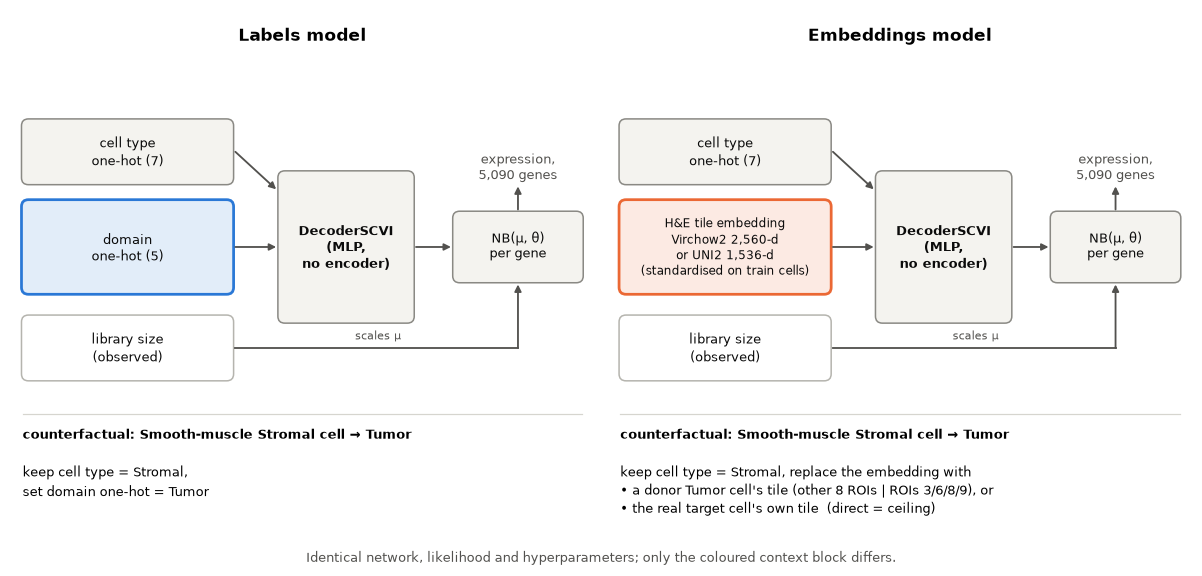

In [3]:
def box(ax, x, y, w, h, text, fc="#f4f3ef", ec="#8a8984", tc="#0b0b0b", lw=1.0, fs=8.5, bold=False):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                         fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc,
            fontweight="bold" if bold else "normal", linespacing=1.3)


def arrow(ax, x0, y0, x1, y1, c="#52514e"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.2, shrinkA=0, shrinkB=0))


def draw_model(ax, title, ctx_text, ctx_color, cf_text, ctx_fs=8.5):
    ax.set_xlim(0, 10); ax.set_ylim(0.6, 10); ax.axis("off")
    ax.text(5, 9.7, title, ha="center", va="top", fontsize=11, fontweight="bold")
    # inputs
    box(ax, 0.2, 7.0, 3.6, 1.1, "cell type\none-hot (7)")
    box(ax, 0.2, 5.1, 3.6, 1.6, ctx_text, fc=ctx_color + "22", ec=ctx_color, lw=1.8, fs=ctx_fs)
    box(ax, 0.2, 3.6, 3.6, 1.1, "library size\n(observed)", fc="white", ec="#b5b4ae")
    # decoder + likelihood
    box(ax, 4.6, 4.6, 2.3, 2.6, "DecoderSCVI\n(MLP,\nno encoder)", bold=True)
    box(ax, 7.6, 5.3, 2.2, 1.2, "NB(μ, θ)\nper gene")
    ax.text(8.7, 7.0, "expression,\n5,090 genes", ha="center", va="bottom", fontsize=8.5, color="#52514e")
    arrow(ax, 8.7, 6.55, 8.7, 6.95)
    for y in (7.55, 5.9):
        arrow(ax, 3.85, y, 4.55, min(max(y, 5.0), 6.9))
    ax.plot([3.85, 8.7], [4.15, 4.15], color="#52514e", lw=1.2)        # library size scales μ
    arrow(ax, 8.7, 4.15, 8.7, 5.25)
    ax.text(6.3, 4.25, "scales μ", ha="center", va="bottom", fontsize=7.5, color="#52514e")
    arrow(ax, 6.95, 5.9, 7.55, 5.9)
    # counterfactual strip
    ax.plot([0.2, 9.8], [3.0, 3.0], color="#d6d5cf", lw=0.8)
    ax.text(0.2, 2.75, "counterfactual: Smooth-muscle Stromal cell → Tumor", fontsize=8.5,
            va="top", fontweight="bold")
    ax.text(0.2, 2.15, cf_text, fontsize=8.5, va="top", linespacing=1.4)


fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
draw_model(axes[0], "Labels model", "domain\none-hot (5)", FAMILY_COLOR["labels"],
           "keep cell type = Stromal,\nset domain one-hot = Tumor")
draw_model(axes[1], "Embeddings model",
           "H&E tile embedding\nVirchow2 2,560-d\nor UNI2 1,536-d\n(standardised on train cells)",
           FAMILY_COLOR["virchow2"],
           "keep cell type = Stromal, replace the embedding with\n"
           "• a donor Tumor cell's tile (other 8 ROIs | ROIs 3/6/8/9), or\n"
           "• the real target cell's own tile  (direct = ceiling)", ctx_fs=7.8)
fig.text(0.5, 0.01, "Identical network, likelihood and hyperparameters; only the coloured "
         "context block differs.", ha="center", fontsize=8.5, color="#52514e")
plt.tight_layout()
save(fig, "fig1_model_diagram")
plt.show()

## 2. Forest / dot plot — the main benchmark at a glance

One row per model. The big marker is the mean over 3 seeds, the bar is ± sd and the small dots are
individual seeds. Path2Space has one run, and its value is also drawn as a dashed reference line.
Filled = counterfactual, hollow = direct (ceiling ◇ / baseline □).

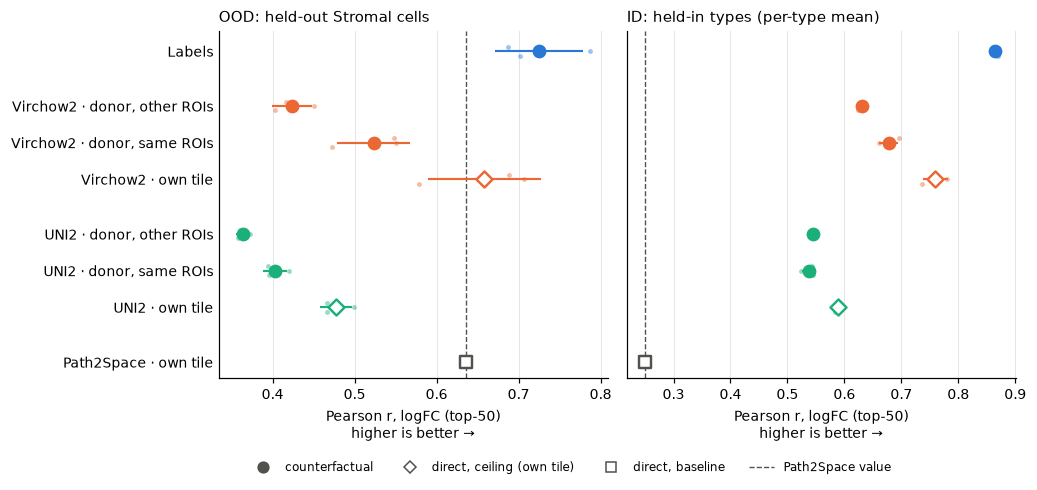

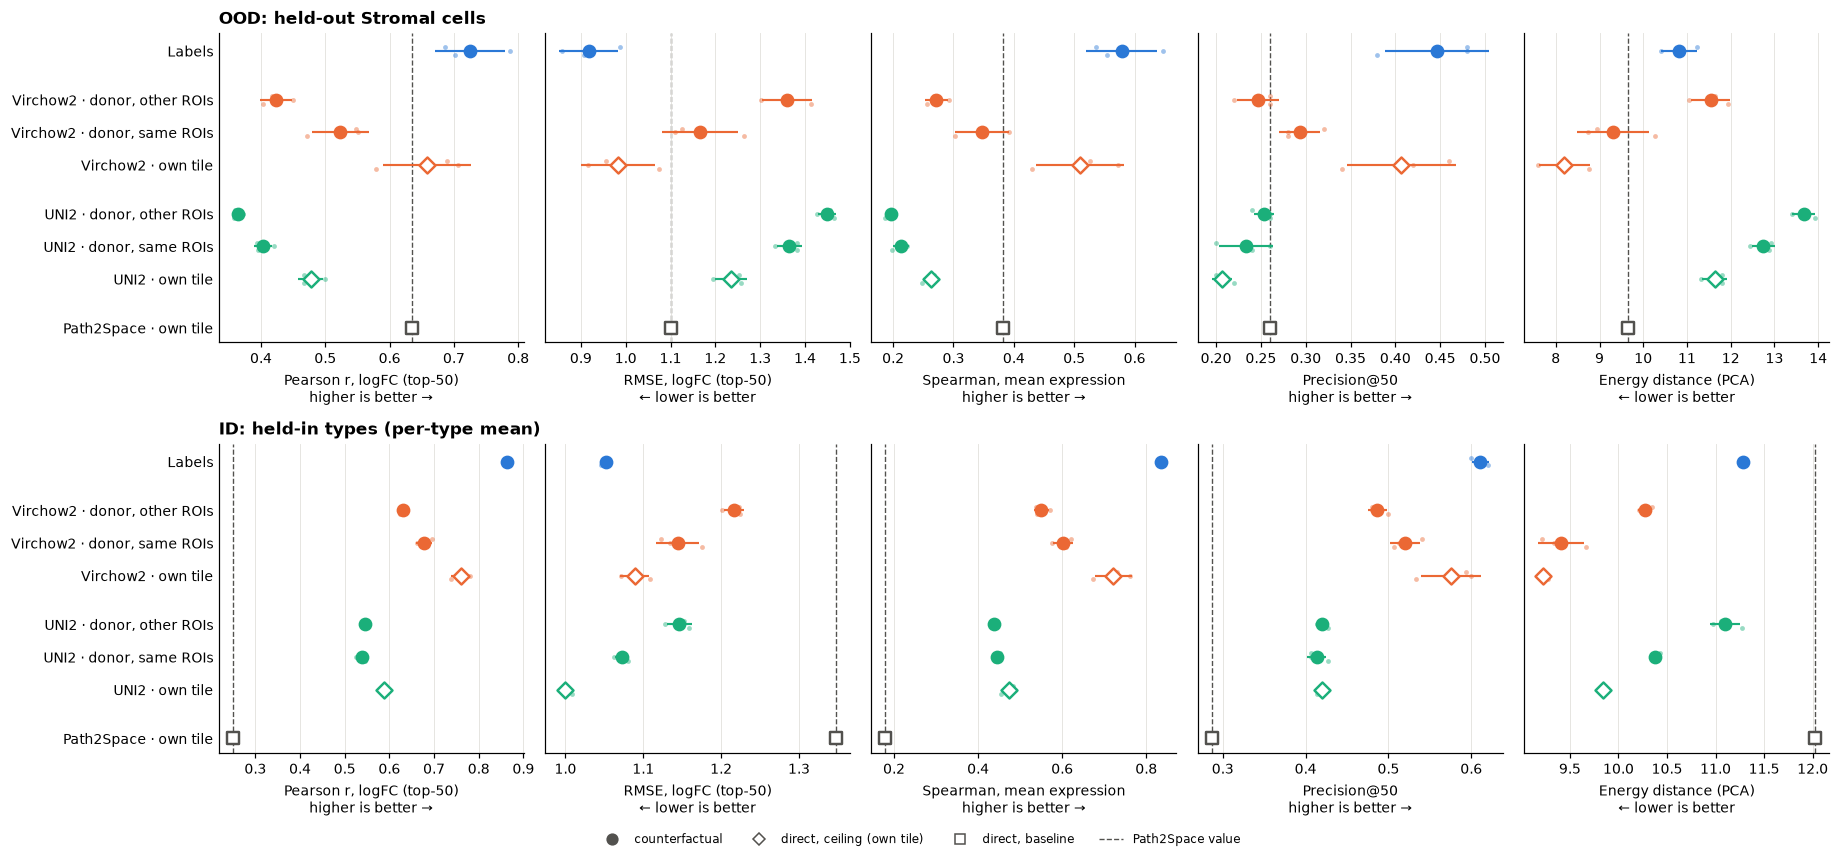

In [4]:
ROW_ORDER = ["labels", "emb_seen_8ROIs", "emb_unseen_ROIs", "emb_ceiling",
             "uni2_emb_seen_8ROIs", "uni2_emb_unseen_ROIs", "uni2_emb_ceiling", "path2space"]
GAPS = {"emb_seen_8ROIs": 0.5, "uni2_emb_seen_8ROIs": 0.5, "path2space": 0.5}  # space between families
ys, y = {}, 0.0
for k in ROW_ORDER:
    y += GAPS.get(k, 0) + (1 if ys else 0)
    ys[k] = y


def forest(ax, regime, metric, labels=True):
    sub = per_seed[per_seed["regime"] == regime]
    for k in ROW_ORDER:
        v = sub.loc[sub["key"] == k, metric].to_numpy()
        c, m = color(k), MARKER(k)
        ax.scatter(v, np.full(len(v), ys[k]) + np.linspace(-0.12, 0.12, len(v)) * (len(v) > 1),
                   s=10, color=c, alpha=0.45, lw=0, zorder=3)
        if len(v) > 1:
            ax.errorbar(v.mean(), ys[k], xerr=v.std(ddof=1), color=c, lw=1.4, capsize=0, zorder=2)
        ax.scatter(v.mean(), ys[k], s=55, marker=m, zorder=4, lw=1.6,
                   facecolor="white" if is_direct(k) else c, edgecolor=c)
    p2s = sub.loc[sub["key"] == "path2space", metric].iloc[0]
    ax.axvline(p2s, color=FAMILY_COLOR["path2space"], ls="--", lw=0.9, zorder=1)
    ax.set_yticks(list(ys.values()))
    if labels:
        ax.set_yticklabels([SHORT[k] for k in ys])
    ax.tick_params(axis="y", labelleft=labels)
    if not ax.yaxis_inverted():   # shared y-axis: invert once, not once per panel
        ax.invert_yaxis()
    ax.xaxis.grid(True, **GRID)
    ax.tick_params(axis="y", length=0)
    arrow_txt = "higher is better →" if HIGHER_BETTER[metric] else "← lower is better"
    ax.set_xlabel(f"{METRIC_LABEL[metric]}\n{arrow_txt}")


legend_handles = [
    Line2D([], [], marker="o", ls="", color="#52514e", mfc="#52514e", ms=7, label="counterfactual"),
    Line2D([], [], marker="D", ls="", color="#52514e", mfc="white", ms=6, label="direct, ceiling (own tile)"),
    Line2D([], [], marker="s", ls="", color="#52514e", mfc="white", ms=6, label="direct, baseline"),
    Line2D([], [], ls="--", color="#52514e", lw=0.9, label="Path2Space value"),
]

# --- 2a: headline metric, both regimes
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=True)
for ax, regime in zip(axes, ["OOD", "ID"]):
    forest(ax, regime, "pearson_logfc", labels=(regime == "OOD"))
    ax.set_title(REGIME_TITLE[regime], loc="left")
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.55, -0.06), fontsize=8)
plt.tight_layout()
save(fig, "fig2a_forest_pearson")
plt.show()

# --- 2a (supplement): all five metrics, both regimes
fig, axes = plt.subplots(2, len(METRICS), figsize=(3.0 * len(METRICS) + 1.8, 7.6), sharey=True)
for i, regime in enumerate(["OOD", "ID"]):
    for j, metric in enumerate(METRICS):
        forest(axes[i, j], regime, metric, labels=(j == 0))
    axes[i, 0].set_title(REGIME_TITLE[regime], loc="left", fontsize=11, fontweight="bold")
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03), fontsize=8)
plt.tight_layout()
save(fig, "fig2a_supp_forest_all_metrics")
plt.show()

## 3. Metric heatmap — does the ranking hold across metrics?

Colour = **score within the column**, min–max scaled so **1 = best model on that metric** (RMSE
and energy distance are flipped first, so darker is always better). Numbers are the raw seed
means. If a model is dark across a whole block, its ranking does not depend on the metric choice.

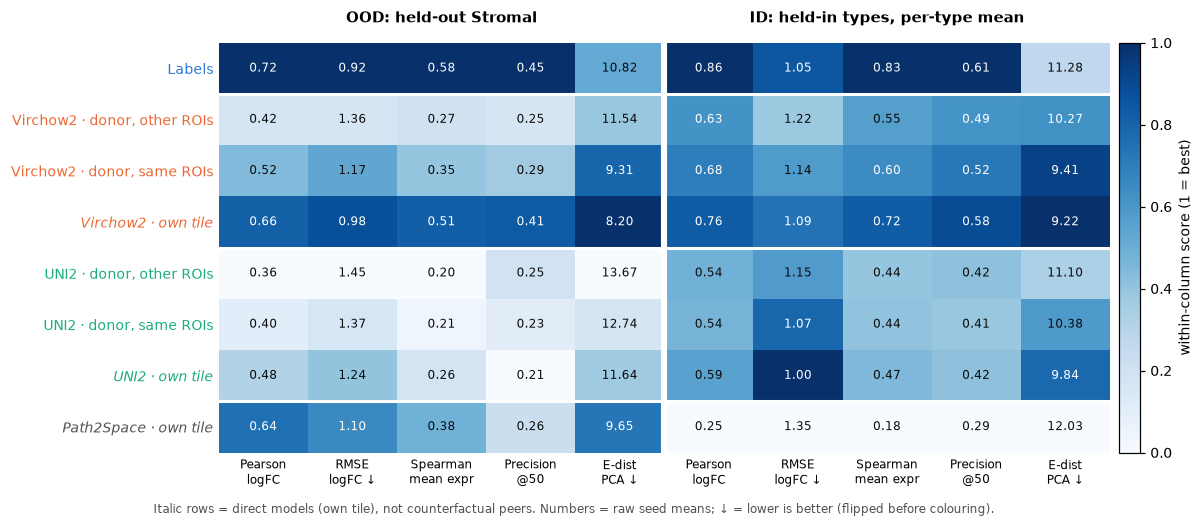

In [5]:
means = per_seed.groupby(["regime", "key"])[METRICS].mean()
cols = [(r, m) for r in ["OOD", "ID"] for m in METRICS]
raw = pd.DataFrame({c: means.loc[c[0]].loc[ROW_ORDER, c[1]] for c in cols})
score = raw.copy()
for (r, m) in cols:
    v = raw[(r, m)] if HIGHER_BETTER[m] else -raw[(r, m)]
    score[(r, m)] = (v - v.min()) / (v.max() - v.min())

fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(score.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(score.shape[0]):
    for j in range(score.shape[1]):
        ax.text(j, i, f"{raw.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if score.iat[i, j] > 0.6 else "#0b0b0b")
short_metric = {"pearson_logfc": "Pearson\nlogFC", "rmse_logfc": "RMSE\nlogFC ↓",
                "spearman_avg": "Spearman\nmean expr", "precision_at_top_n": "Precision\n@50",
                "edistance_pca": "E-dist\nPCA ↓"}
ax.set_xticks(range(len(cols))); ax.set_xticklabels([short_metric[m] for _, m in cols], fontsize=8)
ax.set_yticks(range(len(ROW_ORDER))); ax.set_yticklabels([SHORT[k] for k in ROW_ORDER])
for t, k in zip(ax.get_yticklabels(), ROW_ORDER):
    t.set_color(color(k)); t.set_fontstyle("italic" if is_direct(k) else "normal")
ax.axvline(len(METRICS) - 0.5, color="white", lw=4)
for x, r in [(2, "OOD: held-out Stromal"), (7, "ID: held-in types, per-type mean")]:
    ax.text(x, -0.9, r, ha="center", fontsize=10, fontweight="bold")
for b in [0.5, 3.5, 6.5]:
    ax.axhline(b, color="white", lw=2)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("within-column score (1 = best)")
fig.text(0.13, -0.02, "Italic rows = direct models (own tile), not counterfactual peers. Numbers = raw "
         "seed means; ↓ = lower is better (flipped before colouring).", fontsize=8, color="#52514e")
plt.tight_layout()
save(fig, "fig3_metric_heatmap")
plt.show()

## 4. Information ladder — how much tissue context does the embedding need?

The x-axis is how much information about the *target* tissue the embeddings model receives. It
goes from a generic Tumor tile (donor from the other 8 ROIs), to a tile from the same tumour niche
(donor from ROIs 3/6/8/9), to the target cell's own tile (direct, a ceiling). The Labels model
(blue band = mean ± sd) and Path2Space (grey square, also own tile) are reference levels. If
Virchow2 only reaches Labels at the own-tile rung, then a single domain label carries as much
transferable context as the tile does.

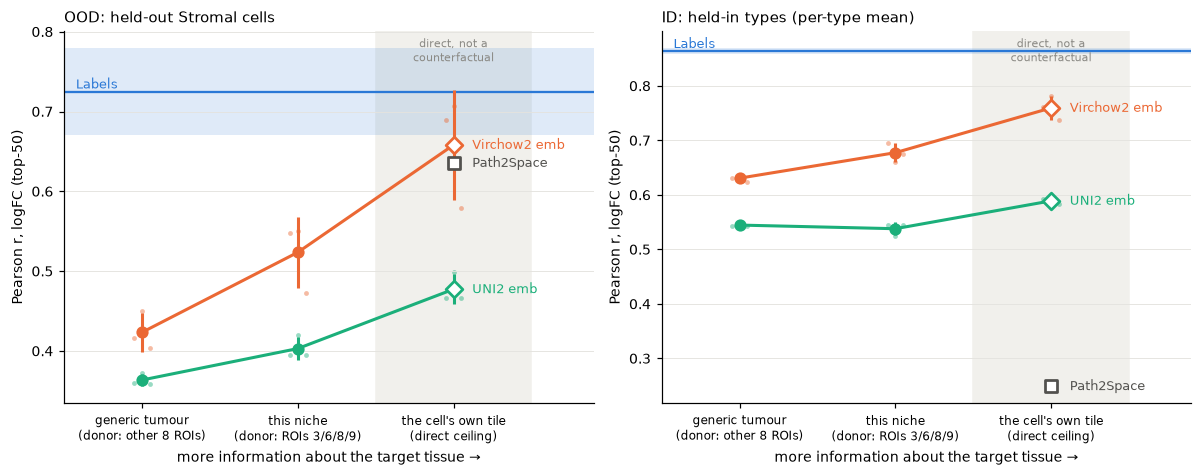

In [6]:
LADDER = {"virchow2": ["emb_seen_8ROIs", "emb_unseen_ROIs", "emb_ceiling"],
          "uni2": ["uni2_emb_seen_8ROIs", "uni2_emb_unseen_ROIs", "uni2_emb_ceiling"]}
XT = ["generic tumour\n(donor: other 8 ROIs)", "this niche\n(donor: ROIs 3/6/8/9)",
      "the cell's own tile\n(direct ceiling)"]


def ladder(ax, regime, metric="pearson_logfc"):
    sub = per_seed[per_seed["regime"] == regime]
    get = lambda k: sub.loc[sub["key"] == k, metric].to_numpy()
    ax.axvspan(1.5, 2.5, color="#f1f0ec", zorder=0)
    ax.text(2, 0.985, "direct, not a\ncounterfactual", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=7.5, color="#8a8984")
    lab = get("labels")
    ax.axhspan(lab.mean() - lab.std(ddof=1), lab.mean() + lab.std(ddof=1),
               color=FAMILY_COLOR["labels"], alpha=0.15, lw=0)
    ax.axhline(lab.mean(), color=FAMILY_COLOR["labels"], lw=1.5)
    ax.text(-0.45, lab.mean(), " Labels", color=FAMILY_COLOR["labels"], va="bottom", fontsize=8.5)
    for fam, keys in LADDER.items():
        c = FAMILY_COLOR[fam]
        vals = [get(k) for k in keys]
        mu = np.array([v.mean() for v in vals]); sd = np.array([v.std(ddof=1) for v in vals])
        for x, v in enumerate(vals):
            ax.scatter(np.full(len(v), x) + np.array([-0.05, 0, 0.05]), v, s=10, color=c, alpha=0.45, lw=0)
        ax.errorbar(range(3), mu, yerr=sd, color=c, lw=2, marker="o", ms=7, capsize=0,
                    mfc=c, label=FAMILY_NAME[fam])
        ax.scatter([2], mu[-1:], s=60, marker="D", facecolor="white", edgecolor=c, lw=1.8, zorder=5)
        ax.text(2.12, mu[-1], f"{FAMILY_NAME[fam]}", color=c, va="center", fontsize=8.5)
    p2s = get("path2space")[0]
    ax.scatter([2.0], [p2s], marker="s", s=60, facecolor="white", edgecolor=FAMILY_COLOR["path2space"],
               lw=1.8, zorder=5)
    ax.text(2.12, p2s, "Path2Space", color=FAMILY_COLOR["path2space"], va="center", fontsize=8.5)
    ax.set_xticks(range(3)); ax.set_xticklabels(XT, fontsize=8)
    ax.set_xlim(-0.5, 2.9)
    ax.yaxis.grid(True, **GRID)
    ax.set_ylabel(METRIC_LABEL[metric])
    ax.set_title(REGIME_TITLE[regime], loc="left")
    ax.set_xlabel("more information about the target tissue →")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, regime in zip(axes, ["OOD", "ID"]):
    ladder(ax, regime)
plt.tight_layout()
save(fig, "fig4_information_ladder")
plt.show()

## 5. Observed vs predicted logFC — density and hexbin versions

These redo the benchmark notebook's scatter (OOD Stromal, shared genes, seed `GENE_SEED`). The
grey cloud there hid how many genes sit at each position. **5a** colours every gene by local point
density, and **5b** bins the genes into hexagons on a log count scale. The top-50 genes the metric
is computed on are drawn on top in both. `r(50)` is the benchmark metric and `r(all)` is over all
3,603 genes. Pick whichever version reads better.

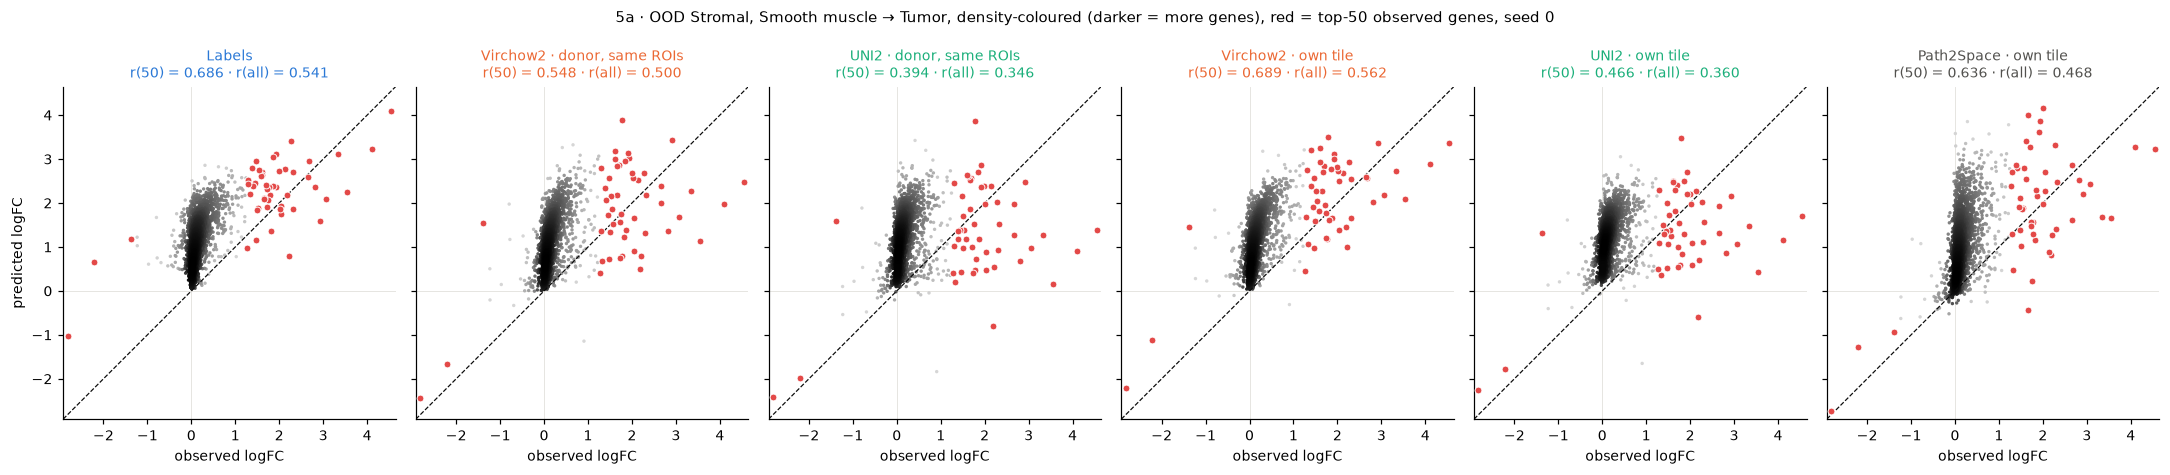

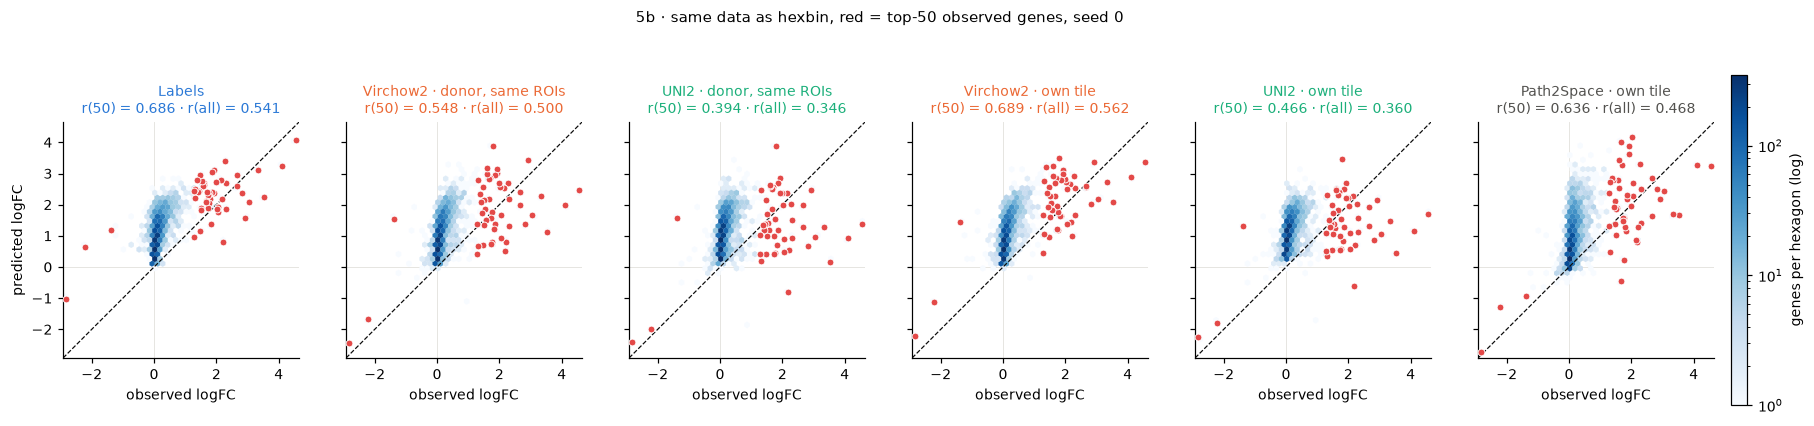

In [7]:
PANELS = ["labels", "emb_unseen_ROIs", "uni2_emb_unseen_ROIs", "emb_ceiling", "uni2_emb_ceiling", "path2space"]
lo = min(OBS_LFC.min(), min(pred_at(k).min() for k in PANELS))
hi = max(OBS_LFC.max(), max(pred_at(k).max() for k in PANELS))
LIM = (lo - 0.1, hi + 0.1)
TOP_C = "#e34948"


def panel_title(ax, k):
    p = pred_at(k)
    ax.set_title(f"{SHORT[k]}\nr(50) = {pearsonr(OBS_LFC[TOP], p[TOP])[0]:.3f} · "
                 f"r(all) = {pearsonr(OBS_LFC, p)[0]:.3f}", fontsize=9, color=color(k))


def finish(ax):
    ax.plot(LIM, LIM, color="#0b0b0b", ls="--", lw=0.8)
    ax.axhline(0, **GRID); ax.axvline(0, **GRID)
    ax.set_xlim(LIM); ax.set_ylim(LIM); ax.set_aspect("equal")


# --- 5a: density-coloured scatter
fig, axes = plt.subplots(1, len(PANELS), figsize=(3.3 * len(PANELS), 3.9), sharex=True, sharey=True)
for ax, k in zip(axes, PANELS):
    p = pred_at(k)
    xy = np.vstack([OBS_LFC, p])
    d = gaussian_kde(xy)(xy)
    o = np.argsort(d)
    sca = ax.scatter(OBS_LFC[o], p[o], c=np.log10(d[o]), s=5, cmap="Greys", vmin=np.log10(d).min() - 1, lw=0)
    ax.scatter(OBS_LFC[TOP], p[TOP], s=20, facecolor=TOP_C, edgecolor="white", lw=0.6, zorder=4)
    finish(ax); panel_title(ax, k)
    ax.set_xlabel("observed logFC")
axes[0].set_ylabel("predicted logFC")
fig.suptitle(f"5a · OOD Stromal, Smooth muscle → Tumor, density-coloured (darker = more genes), "
             f"red = top-{TOP_N} observed genes, seed {GENE_SEED}", y=1.03, fontsize=10)
plt.tight_layout()
save(fig, "fig5a_scatter_density")
plt.show()

# --- 5b: hexbin
fig, axes = plt.subplots(1, len(PANELS), figsize=(3.3 * len(PANELS), 3.9), sharex=True, sharey=True)
for ax, k in zip(axes, PANELS):
    p = pred_at(k)
    hb = ax.hexbin(OBS_LFC, p, gridsize=45, extent=(*LIM, *LIM), bins="log", cmap="Blues", mincnt=1, lw=0.1)
    ax.scatter(OBS_LFC[TOP], p[TOP], s=20, facecolor=TOP_C, edgecolor="white", lw=0.6, zorder=4)
    finish(ax); panel_title(ax, k)
    ax.set_xlabel("observed logFC")
axes[0].set_ylabel("predicted logFC")
cb = fig.colorbar(hb, ax=axes, fraction=0.012, pad=0.01); cb.set_label("genes per hexagon (log)")
fig.suptitle(f"5b · same data as hexbin, red = top-{TOP_N} observed genes, seed {GENE_SEED}",
             y=1.03, fontsize=10)
save(fig, "fig5b_scatter_hexbin")
plt.show()

### 5c. Hexbin, paper version: counterfactual models + Path2Space

Same as 5b, without the embeddings own-tile ceilings. The embeddings rows use the donor from the
held-out ROIs 3/6/8/9, and the panel titles use plain model names.

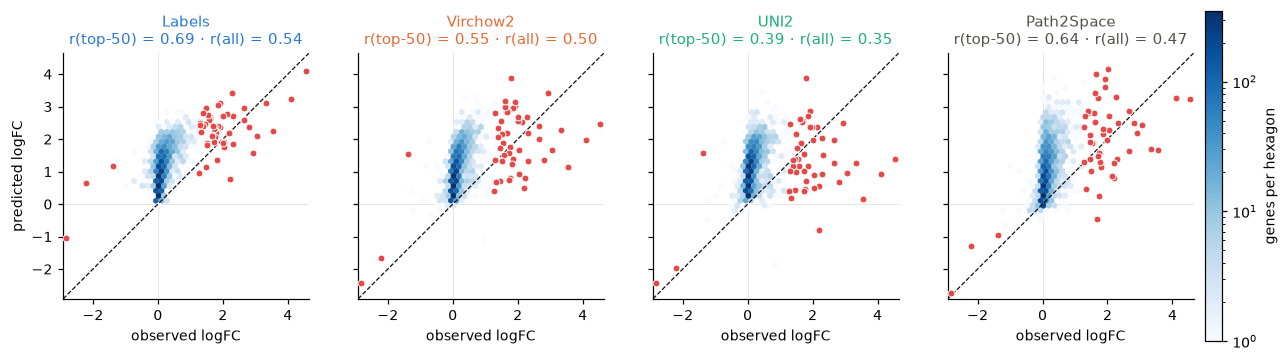

In [8]:
# Plain model names for paper figures (the panel/legend text; the full setting goes in the caption).
PAPER_NAME = {"labels": "Labels", "emb_unseen_ROIs": "Virchow2",
              "uni2_emb_unseen_ROIs": "UNI2", "path2space": "Path2Space"}
PAPER_PANELS = list(PAPER_NAME)
lo = min(OBS_LFC.min(), min(pred_at(k).min() for k in PAPER_PANELS))
hi = max(OBS_LFC.max(), max(pred_at(k).max() for k in PAPER_PANELS))
LIM_P = (lo - 0.1, hi + 0.1)

fig, axes = plt.subplots(1, len(PAPER_PANELS), figsize=(3.4 * len(PAPER_PANELS), 3.9),
                         sharex=True, sharey=True)
for ax, k in zip(axes, PAPER_PANELS):
    p = pred_at(k)
    hb = ax.hexbin(OBS_LFC, p, gridsize=45, extent=(*LIM_P, *LIM_P), bins="log", cmap="Blues",
                   mincnt=1, lw=0.1)
    ax.scatter(OBS_LFC[TOP], p[TOP], s=20, facecolor=TOP_C, edgecolor="white", lw=0.6, zorder=4)
    ax.plot(LIM_P, LIM_P, color="#0b0b0b", ls="--", lw=0.8)
    ax.axhline(0, **GRID); ax.axvline(0, **GRID)
    ax.set_xlim(LIM_P); ax.set_ylim(LIM_P); ax.set_aspect("equal")
    ax.set_title(f"{PAPER_NAME[k]}\nr(top-50) = {pearsonr(OBS_LFC[TOP], p[TOP])[0]:.2f} · "
                 f"r(all) = {pearsonr(OBS_LFC, p)[0]:.2f}", fontsize=9.5, color=color(k))
    ax.set_xlabel("observed logFC")
axes[0].set_ylabel("predicted logFC")
cb = fig.colorbar(hb, ax=axes, fraction=0.015, pad=0.01)
cb.set_label("genes per hexagon")
save(fig, "fig5c_scatter_hexbin_paper")
plt.show()

**Figure 5c (draft caption).** **Predicted versus observed expression change of held-out Stromal
cells between Smooth muscle and Tumor.** Each panel compares, gene by gene, the observed log
fold-change (logFC; x-axis) with a model's predicted logFC (y-axis) for Stromal cells moving from
Smooth muscle into Tumor, over the 3,603 genes shared by the Xenium panel and Path2Space. Observed
logFC is the difference in mean log1p(CPM/10⁴) expression between the 560 Stromal cells in the
held-out Tumor ROIs (3, 6, 8, 9) and the 2,538 Stromal cells in Smooth muscle. Predicted logFC is
computed against the same observed Smooth-muscle cells. **Labels**, **Virchow2** and **UNI2** are
counterfactual predictions: the 2,538 Smooth-muscle Stromal cells are passed through a decoder
trained without any Stromal-in-Tumor cell or any cell from the held-out ROIs. Their context input
is changed to Tumor, either by switching the one-hot domain label (Labels), or by replacing each
cell's H&E tile embedding with that of a randomly drawn non-Stromal Tumor cell from the held-out
ROIs (Virchow2, UNI2). **Path2Space**, an external H&E-to-expression model trained on breast-cancer
Visium data, predicts the 560 target Stromal cells directly from their own H&E tiles and is shown
as a reference. Hexagons are shaded by the number of genes they contain (log scale). Red points
are the 50 genes with the largest observed |logFC|, on which the benchmark metrics are computed;
r(top-50) and r(all) are the Pearson correlations over these 50 genes and over all 3,603 genes.
Dashed line, y = x. Training seed 0 is shown; mean ± s.d. over three seeds is reported in Table C3.
Across models, genes with little observed change lie above the diagonal. This systematic positive
offset arises because the observed counts are sparse while the predictions are dense NB means, so
log-averaging inflates predicted expression of lowly expressed genes (see Fig. 6b).

## 6. Bland–Altman — where are the predictions biased?

This plot checks the note in the benchmark notebook: *the genes outside the top-50 are mostly
over-estimated*. The y-axis is always **error = predicted − observed logFC**. Above 0 means the
model predicts a larger change than was measured.

- **6a, classic Bland–Altman.** x = (observed + predicted)/2. If the band tilts, the error grows
  with the size of the effect, i.e. the predictions are systematically shrunk or inflated.
- **6b, MA-style.** x = the gene's mean observed log-expression. If the bias depends on expression
  level, low-expression genes are being pushed up. That points to a library-size/CPM or NB-floor
  effect rather than to biology.

Black line = running median of the error in 30 x-quantile bins. The table under the plots gives the
median error and the fraction of over-estimated genes, top-50 vs the rest.

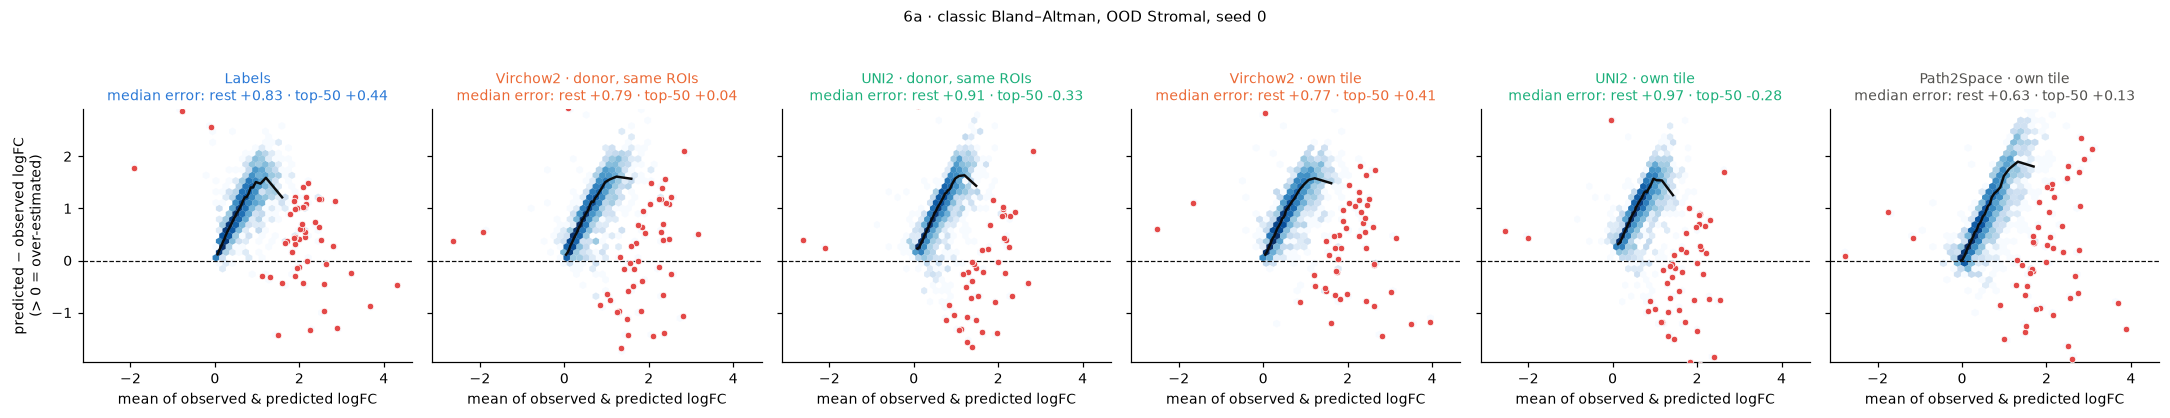

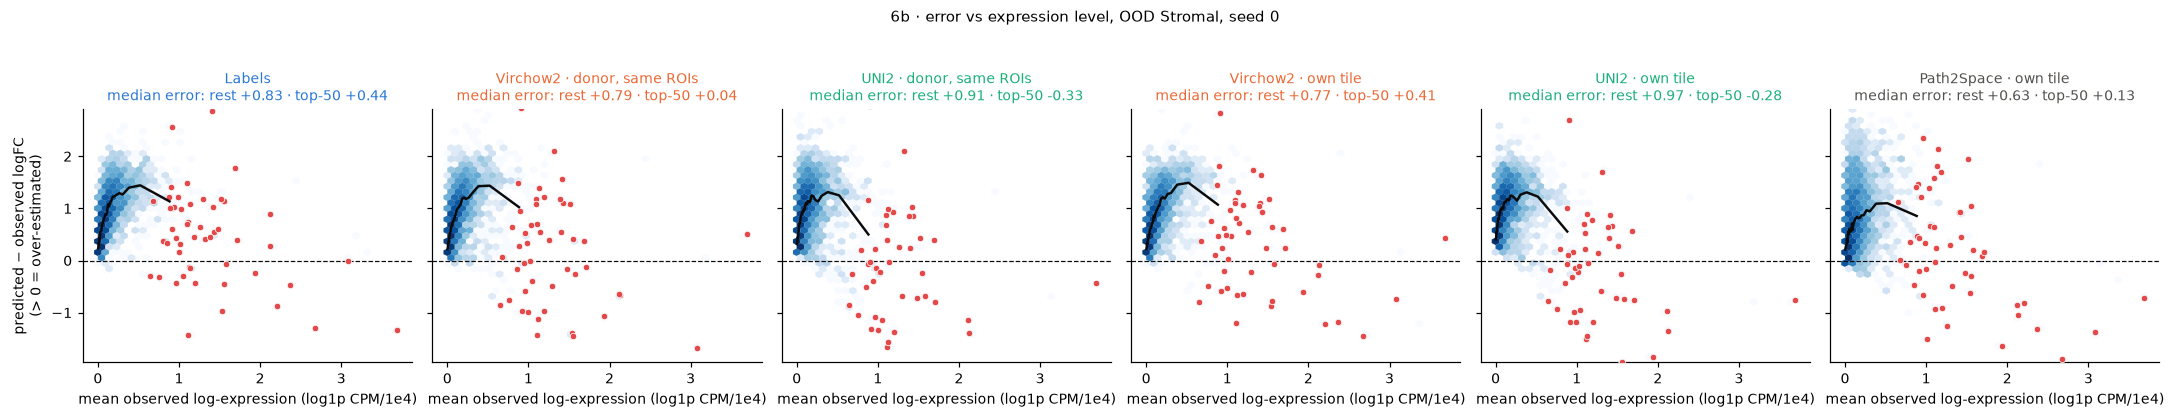

median_error        frac_overestimated         \
genes                              top-50   rest             top-50   rest   
model                                                                        
Labels                              0.360  0.870              0.700  0.998   
Virchow2 · donor, other ROIs       -0.143  0.777              0.480  0.985   
Virchow2 · donor, same ROIs        -0.007  0.772              0.507  0.991   
Virchow2 · own tile                 0.297  0.769              0.587  0.996   
UNI2 · donor, other ROIs           -0.296  0.861              0.367  0.983   
UNI2 · donor, same ROIs            -0.342  0.913              0.373  0.988   
UNI2 · own tile                    -0.282  0.969              0.393  0.992   
Path2Space · own tile               0.132  0.625              0.540  0.946   

                             mean_abs_error         
genes                                top-50   rest  
model                                               
Labels                                0.717  0.890  
Virchow2 · donor, other ROIs          1.073  0.825  
Virchow2 · donor, same ROIs           0.943  0.820  
Virchow2 · own tile                   0.793  0.818  
UNI2 · donor, other ROIs              1.115  0.891  
UNI2 · donor, same ROIs               1.049  0.924  
UNI2 · own tile                       0.948  0.965  
Path2Space · own tile                 0.902  0.749

In [9]:
def running_median(x, y, nbins=30):
    edges = np.quantile(x, np.linspace(0, 1, nbins + 1))
    idx = np.clip(np.digitize(x, edges[1:-1]), 0, nbins - 1)
    cx = np.array([np.median(x[idx == i]) for i in range(nbins)])
    cy = np.array([np.median(y[idx == i]) for i in range(nbins)])
    return cx, cy


def bland_altman(xfun, xlabel, name, title):
    fig, axes = plt.subplots(1, len(PANELS), figsize=(3.3 * len(PANELS), 3.6), sharex=True, sharey=True)
    ylim = np.quantile(np.concatenate([pred_at(k) - OBS_LFC for k in PANELS]), [0.001, 0.999])
    ylim = (ylim[0] - 0.2, ylim[1] + 0.2)
    for ax, k in zip(axes, PANELS):
        err = pred_at(k) - OBS_LFC
        x = xfun(k)
        ax.hexbin(x, err, gridsize=40, bins="log", cmap="Blues", mincnt=1, lw=0.1,
                  extent=(x.min(), x.max(), *ylim))
        ax.scatter(x[TOP], err[TOP], s=18, facecolor=TOP_C, edgecolor="white", lw=0.5, zorder=4)
        cx, cy = running_median(x, err)
        ax.plot(cx, cy, color="#0b0b0b", lw=1.6, zorder=5)
        ax.axhline(0, color="#0b0b0b", ls="--", lw=0.8)
        ax.set_ylim(ylim)
        ax.set_title(f"{SHORT[k]}\nmedian error: rest {np.median(err[~is_top]):+.2f} · "
                     f"top-50 {np.median(err[is_top]):+.2f}", fontsize=9, color=color(k))
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel("predicted − observed logFC\n(> 0 = over-estimated)")
    fig.suptitle(title, y=1.04, fontsize=10)
    plt.tight_layout()
    save(fig, name)
    plt.show()


bland_altman(lambda k: (OBS_LFC + pred_at(k)) / 2, "mean of observed & predicted logFC",
             "fig6a_bland_altman", f"6a · classic Bland–Altman, OOD Stromal, seed {GENE_SEED}")
bland_altman(lambda k: OBS_MEAN, "mean observed log-expression (log1p CPM/1e4)",
             "fig6b_bland_altman_MA", f"6b · error vs expression level, OOD Stromal, seed {GENE_SEED}")

bias = []
for k in MODELS:
    for s, p in enumerate(PRED_LFC[k]):
        err = p - OBS_LFC
        for grp, m in [("top-50", is_top), ("rest", ~is_top)]:
            bias.append({"model": SHORT[k], "seed": s, "genes": grp, "median_error": np.median(err[m]),
                         "frac_overestimated": (err[m] > 0).mean(), "mean_abs_error": np.abs(err[m]).mean()})
bias = (pd.DataFrame(bias).groupby(["model", "genes"], sort=False)
        [["median_error", "frac_overestimated", "mean_abs_error"]].mean().round(3))
bias.to_csv(os.path.join(FIG_DIR, "table_bias_top50_vs_rest.csv"))
bias.unstack("genes")

**Reading 6b: the over-estimation is a scoring artefact, not a model failure (checked 2026-10-07).**
For *every* model, Path2Space included, ~99 % of the non-top-50 genes are over-estimated, by roughly
+0.8 logFC, and the bias is largest for **lowly expressed** genes. That is the signature of a
**Jensen gap**, not of biology:

- the observed cells are raw integer counts, **98.6 % zeros**. The mean of `log1p(CPM)` over cells is
  pulled down hard by the zeros;
- the predictions are NB **means** (smooth, **0 % zeros**). `log1p` of a smooth mean is always larger
  than the mean of `log1p` of sparse draws with the same expectation.

Because `observed_control` puts the *observed* control mean on both sides, predicted logFC =
`mean log1p(pred target) − mean log1p(observed control)`. That carries the gap for every gene, and
the gap is largest where counts are sparsest. The top-50 genes are highly expressed, so the gap
matters less there, which is why the top-50 metrics look fine.

Possible fixes for the benchmark (not applied here): (i) sample counts from the predicted NB before
scoring, or (ii) compute logFC on log(mean CPM) instead of mean(log1p CPM), for observed and
predicted alike.

## 7. Robustness to the top-N cutoff — precision@k and Pearson@k

The benchmark fixes the cutoff at **50 genes**. These curves sweep it so a reader can see the
conclusions do not depend on that choice.

- **Precision@k** = of the k genes with the largest |observed logFC|, the fraction that are also
  among the model's k largest |predicted logFC|. Dotted line = random expectation k/3,603.
- **Pearson@k** = the benchmark's `pearson_logfc` computed on the top-k observed genes.

k starts at 10 (Pearson on < 10 genes is noise). Mean ± sd over 3 seeds (Path2Space: one run). OOD Stromal only. Donor-from-other-ROIs rows are
left out to keep the plot readable (they are the weakest rung in §4).

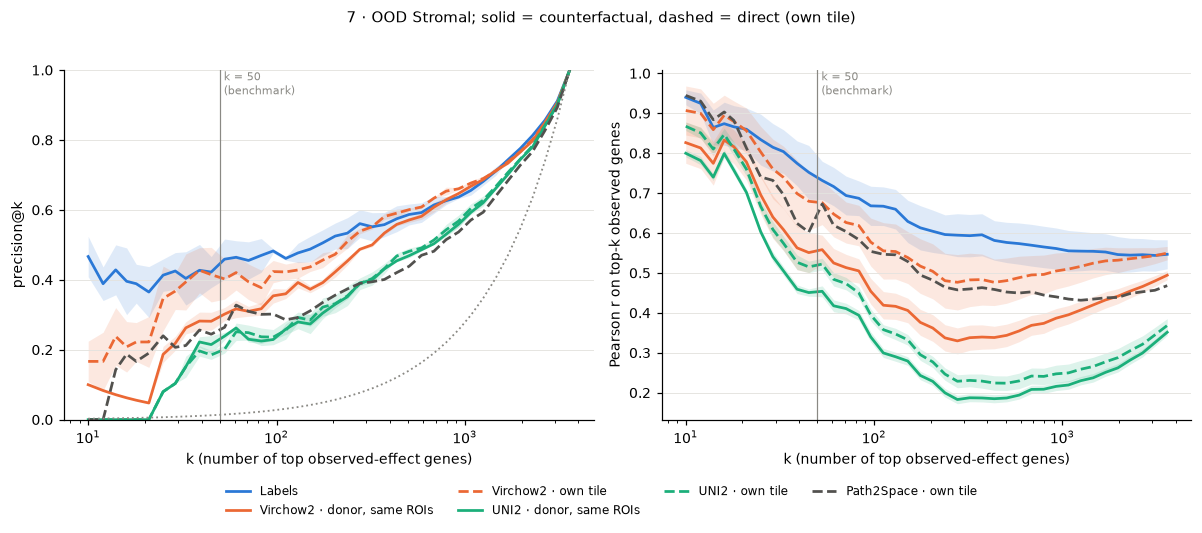

In [10]:
KS = np.unique(np.round(np.geomspace(10, len(SHARED_GENES), 40)).astype(int))
CURVE_MODELS = ["labels", "emb_unseen_ROIs", "emb_ceiling", "uni2_emb_unseen_ROIs", "uni2_emb_ceiling", "path2space"]
rank_obs = np.argsort(-np.abs(OBS_LFC))


def prec_at_k(p, k):
    return len(set(rank_obs[:k]) & set(np.argsort(-np.abs(p))[:k])) / k


def pear_at_k(p, k):
    return pearsonr(OBS_LFC[rank_obs[:k]], p[rank_obs[:k]])[0]


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k in CURVE_MODELS:
    c, ls = color(k), ("--" if is_direct(k) else "-")
    for ax, f in zip(axes, [prec_at_k, pear_at_k]):
        M = np.array([[f(p, kk) for kk in KS] for p in PRED_LFC[k]])
        mu = M.mean(0)
        ax.plot(KS, mu, color=c, ls=ls, lw=1.8, label=SHORT[k])
        if len(M) > 1:
            ax.fill_between(KS, mu - M.std(0, ddof=1), mu + M.std(0, ddof=1), color=c, alpha=0.15, lw=0)
axes[0].plot(KS, KS / len(SHARED_GENES), color="#8a8984", ls=":", lw=1.2, label="random")
for ax, yl in zip(axes, ["precision@k", "Pearson r on top-k observed genes"]):
    ax.set_xscale("log")
    ax.axvline(TOP_N, color="#8a8984", lw=0.8)
    ax.text(TOP_N, 1.0, f" k = {TOP_N}\n (benchmark)", transform=ax.get_xaxis_transform(),
            fontsize=7.5, color="#8a8984", va="top")
    ax.set_xlabel("k (number of top observed-effect genes)")
    ax.set_ylabel(yl)
    ax.yaxis.grid(True, **GRID)
axes[0].set_ylim(0, 1)
fig.legend(*axes[1].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8,
           bbox_to_anchor=(0.5, -0.1))
fig.suptitle("7 · OOD Stromal; solid = counterfactual, dashed = direct (own tile)", y=1.02, fontsize=10)
plt.tight_layout()
save(fig, "fig7_precision_pearson_at_k")
plt.show()

## 7b. Every benchmark metric as a function of k

This is the same idea as §7, applied to **all five metrics in the tables**. In the benchmark each
one is computed on the top-50 observed-effect genes (`compare_adatas`, `top_n=50`). Here the cutoff
k is swept from 10 to all 3,603 shared genes, and everything else is computed exactly as in the
benchmark:

| metric | what is compared on the top-k genes | better |
|---|---|---|
| Pearson r, logFC | observed vs predicted logFC (Stromal: Smooth muscle → Tumor) | ↑ |
| RMSE, logFC | same vectors, root-mean-square difference | ↓ |
| Spearman, mean expression | rank agreement of per-gene mean log-expression, observed vs predicted Tumor Stromal cells | ↑ |
| Precision@k | overlap of the top-k observed and top-k predicted genes | ↑ |
| Energy distance (PCA) | distance between the observed and predicted *cell clouds*, PCA (≤ 50 PCs) of the top-k genes | ↓ |

**Models:** Labels, Virchow2 and UNI2 with a **donor from the same ROIs (3/6/8/9)**, and
Path2Space. The embeddings **own-tile** rows (a ceiling, not a peer) and the **donor from the other
ROIs** rows are not drawn. Path2Space is kept as the external baseline, although it is also an
own-tile model (dashed). OOD Stromal only. The lines are means over 3 seeds and the band is ± sd
(Path2Space has one run). The vertical line marks k = 50, where every curve must equal the
benchmark table; the cell checks this.

This is slow the first time (the energy distance is recomputed for every k, seed and model), so
the result is cached to `PRED_DIR/plotting_metrics_vs_k_ood.csv`.

In [11]:
from metrics import (_log1p_norm, pearson_logfc, rmse_logfc, spearman_avg,
                     precision_at_top_n, edistance_pca)

K_MODELS = ["labels", "emb_unseen_ROIs", "emb_seen_8ROIs",
            "uni2_emb_unseen_ROIs", "uni2_emb_seen_8ROIs", "path2space"]
KS_ALL = np.unique(np.r_[np.round(np.geomspace(10, len(SHARED_GENES), 24)).astype(int), TOP_N])
K_CACHE = os.path.join(PRED_DIR, "plotting_metrics_vs_k_ood.csv")


def metrics_vs_k(obs_ctrl_mean, obs_log, pred_log, ks):
    """compare_adatas' five metrics at each top-k cutoff (observed_control baseline)."""
    obs_lfc = obs_log.mean(0) - obs_ctrl_mean
    pred_lfc = pred_log.mean(0) - obs_ctrl_mean
    order = np.argsort(-np.abs(obs_lfc))
    rows = []
    for k in ks:
        idx = order[:k]
        rows.append({
            "k": k,
            "pearson_logfc": pearson_logfc(obs_lfc[idx], pred_lfc[idx]),
            "rmse_logfc": rmse_logfc(obs_lfc[idx], pred_lfc[idx]),
            "spearman_avg": spearman_avg(obs_log[:, idx], pred_log[:, idx]),
            "precision_at_top_n": precision_at_top_n(obs_lfc, pred_lfc, n=k),
            "edistance_pca": edistance_pca(obs_log[:, idx], pred_log[:, idx], n_pcs=50),
        })
    return pd.DataFrame(rows)


if os.path.exists(K_CACHE):
    vs_k = pd.read_csv(K_CACHE)
else:
    observed = read_h5ad_compat(os.path.join(PRED_DIR, "observed.h5ad"))
    o = ood(observed[:, SHARED_GENES])
    ctrl = o.obs[PERT_COL].to_numpy(dtype=str) == CONTROL_LABEL
    o_log = _log1p_norm(o.X).astype(np.float64)
    obs_ctrl_mean, obs_log = o_log[ctrl].mean(0), o_log[~ctrl]
    parts = []
    for key in K_MODELS:
        seeds = MODELS[key][2]
        for seed in (seeds if seeds is not None else [None]):
            p = ood(load_pred(key, seed)[:, SHARED_GENES])
            p_log = _log1p_norm(p.X[p.obs[PERT_COL].to_numpy(dtype=str) != CONTROL_LABEL]).astype(np.float64)
            df = metrics_vs_k(obs_ctrl_mean, obs_log, p_log, KS_ALL)
            parts.append(df.assign(key=key, seed=-1 if seed is None else seed))
            print(f"{key:22s} seed {seed}: done")
    vs_k = pd.concat(parts, ignore_index=True)
    vs_k.to_csv(K_CACHE, index=False)

# Check: at k = 50 every curve must reproduce the benchmark table (Table C2/C3 OOD, per seed).
ref = per_seed[per_seed["regime"] == "OOD"].set_index(["key", "seed"])[METRICS]
at50 = vs_k[vs_k["k"] == TOP_N].set_index(["key", "seed"])[METRICS]
max_diff = (at50 - ref.loc[at50.index]).abs().to_numpy().max()
print(f"max |diff| at k={TOP_N} vs benchmark per-seed CSV, {len(at50)} runs x 5 metrics: {max_diff:.2e}")
assert max_diff < 1e-6

max |diff| at k=50 vs benchmark per-seed CSV, 16 runs x 5 metrics: 0.00e+00


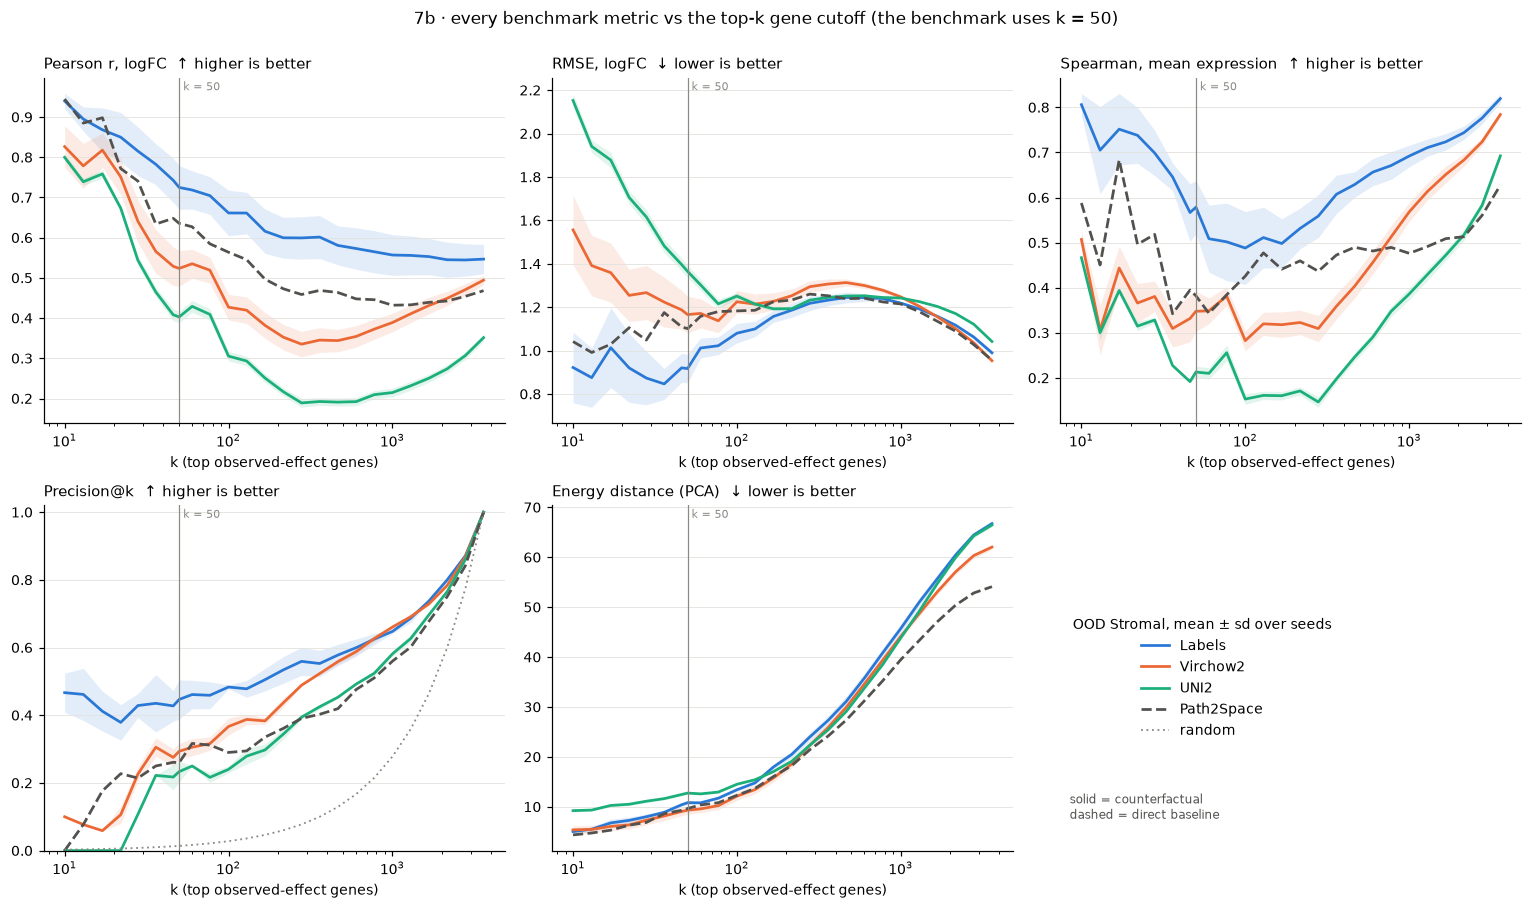

In [12]:
# Plotted: donor from the SAME ROIs (3/6/8/9) only. The "other ROIs" donor rows stay in the cache
# (and in the k = 50 check above) but are not drawn.
PLOT_K_MODELS = ["labels", "emb_unseen_ROIs", "uni2_emb_unseen_ROIs", "path2space"]
LS = {"labels": "-", "emb_unseen_ROIs": "-", "uni2_emb_unseen_ROIs": "-", "path2space": "--"}

fig, axes = plt.subplots(2, 3, figsize=(14, 8.2))
axes = axes.ravel()
for ax, metric in zip(axes, METRICS):
    for key in PLOT_K_MODELS:
        g = vs_k[vs_k["key"] == key].groupby("k")[metric]
        mu, sd = g.mean(), g.std(ddof=1)
        ax.plot(mu.index, mu.values, color=color(key), ls=LS[key], lw=1.8, label=PAPER_NAME[key])
        if sd.notna().any():
            ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, color=color(key), alpha=0.13, lw=0)
    if metric == "precision_at_top_n":
        ax.plot(KS_ALL, KS_ALL / len(SHARED_GENES), color="#8a8984", ls=(0, (1, 2)), lw=1.2, label="random")
        ax.set_ylim(0, 1.02)
    ax.set_xscale("log")
    ax.axvline(TOP_N, color="#8a8984", lw=0.8)
    ax.text(TOP_N, 0.99, f" k = {TOP_N}", transform=ax.get_xaxis_transform(),
            fontsize=7.5, color="#8a8984", va="top")
    ax.yaxis.grid(True, **GRID)
    ax.set_title(f"{METRIC_LABEL[metric].replace(' (top-50)', '').replace('@50', '@k')}  "
                 f"{'↑ higher is better' if HIGHER_BETTER[metric] else '↓ lower is better'}",
                 loc="left", fontsize=9.5)
    ax.set_xlabel("k (top observed-effect genes)")

leg = axes[-1]
leg.axis("off")
handles, labels = axes[3].get_legend_handles_labels()
leg.legend(handles, labels, loc="center left", fontsize=9, title="OOD Stromal, mean ± sd over seeds",
           title_fontsize=9)
leg.text(0.02, 0.08, "solid = counterfactual\ndashed = direct baseline",
         transform=leg.transAxes, fontsize=8, color="#52514e", va="bottom")
fig.suptitle("7b · every benchmark metric vs the top-k gene cutoff (the benchmark uses k = 50)",
             y=1.0, fontsize=11)
plt.tight_layout()
save(fig, "fig7b_all_metrics_vs_k")
plt.show()

**Figure 7b (draft caption).** **Benchmark metrics as a function of the number of top
differentially expressed genes.** For held-out Stromal cells (Smooth muscle → Tumor), each of the
five benchmark metrics is recomputed on the k genes with the largest observed |logFC|, for k from 10
to all 3,603 shared genes (24 log-spaced values plus k = 50, the cutoff used in the benchmark
tables; vertical grey line). **Pearson r** and **RMSE** compare observed and predicted logFC over the
k genes. **Spearman** is the rank correlation of mean log-expression of observed and predicted Tumor
Stromal cells over the k genes. **Precision@k** is the fraction of a model's k largest predicted
|logFC| genes (chosen from all genes) that are among the k largest observed. The grey dotted line
is the random expectation, k/3,603. **Energy distance** is the distance between the observed and
predicted cell populations after PCA (up to 50 components) of the k genes. Arrows in the panel
titles show which direction is better. Labels, Virchow2 and UNI2 (solid) are counterfactual
predictions from Smooth-muscle Stromal cells as in Fig. 5c. Lines are the mean over three training
seeds and the shaded bands ± 1 s.d. Path2Space (dashed) is a single deterministic run that
predicts the target cells directly from their own H&E tiles. At k = 50 all curves reproduce the
benchmark table values exactly.

## 8. Top-50 genes — observed vs predicted logFC

Rows = the benchmark's 50 top observed-effect genes for OOD Stromal, sorted by observed logFC
(up in Tumor at the top). Columns = observed, then each model's predicted logFC for seed
`GENE_SEED` against the same observed Smooth-muscle baseline. Read across a row: the right model
reproduces the colour of the *observed* column. A dot marks a gene that is also in that model's own
top-50 predicted changes (the genes precision@50 counts).

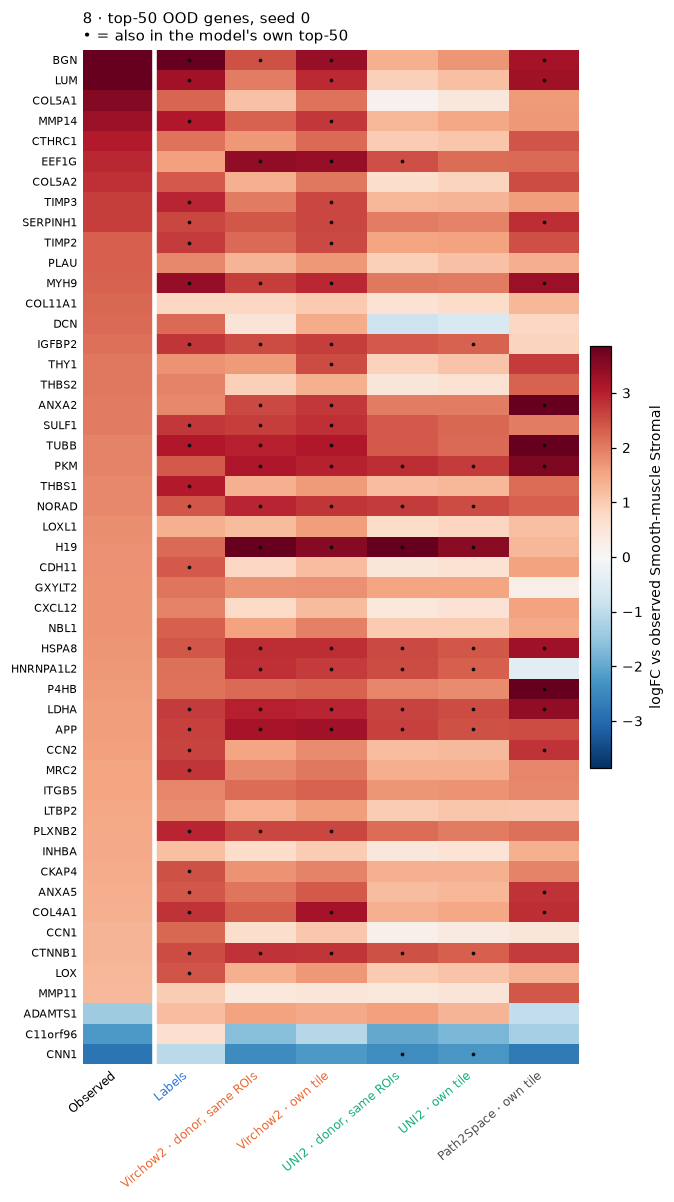

In [13]:
HM_MODELS = ["labels", "emb_unseen_ROIs", "emb_ceiling", "uni2_emb_unseen_ROIs", "uni2_emb_ceiling", "path2space"]
order = TOP[np.argsort(-OBS_LFC[TOP])]
M = np.column_stack([OBS_LFC[order]] + [pred_at(k)[order] for k in HM_MODELS])
vmax = np.quantile(np.abs(M), 0.98)

fig, ax = plt.subplots(figsize=(6.2, 11))
im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
for j, k in enumerate(HM_MODELS, start=1):
    ptop = set(np.argsort(-np.abs(pred_at(k)))[:TOP_N])
    hit = [i for i, g in enumerate(order) if g in ptop]
    ax.scatter([j] * len(hit), hit, s=6, color="#0b0b0b", lw=0)
ax.set_yticks(range(len(order))); ax.set_yticklabels(np.array(SHARED_GENES)[order], fontsize=7)
ax.set_xticks(range(M.shape[1]))
ax.set_xticklabels(["Observed"] + [SHORT[k] for k in HM_MODELS], rotation=40, ha="right", fontsize=8)
for t, k in zip(ax.get_xticklabels()[1:], HM_MODELS):
    t.set_color(color(k))
ax.axvline(0.5, color="white", lw=3)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, shrink=0.5)
cb.set_label("logFC vs observed Smooth-muscle Stromal")
ax.set_title(f"8 · top-{TOP_N} OOD genes, seed {GENE_SEED}\n• = also in the model's own top-{TOP_N}",
             fontsize=9.5, loc="left")
plt.tight_layout()
save(fig, "fig8_top50_heatmap")
plt.show()

## 9. Do the models predict different profiles for different cells?

Path2Space was reported to predict almost the same profile for every cell (cell–cell r ≈ 0.99).
This section checks that claim for every model and asks whether the **cell type** is visible in the
predictions.

For each model we take its predicted **Tumor** cells (counterfactual models: the Smooth-muscle cells
moved into Tumor; Path2Space: the real Tumor cells of ROIs 3/6/8/9, predicted from their own tiles;
Observed: those same real cells, measured). Up to `N_PER` cells per cell type are drawn, profiles are
log1p(CPM/10⁴) over the 3,603 shared genes, and the Pearson correlation is computed between every
pair of cells.

- **Raw** correlation (left of 9b) is dominated by the expression profile that *all* cells share.
  Any smooth prediction scores ≈ 1 on it, so on its own it does not show that a model ignores cell
  type.
- **Gene-centred** correlation (9a): each gene's mean over the shown cells is subtracted first, so
  only differences between cells remain. Blocks on the diagonal = cells of the same type look alike.
- **η² (cell type)** (right of 9b) = the share of the gene-centred variance between cells that is
  explained by cell type (between-type sum of squares / total, summed over genes).

Labels is the obvious extreme: its input is only (cell type, domain), so after CPM every cell of
one type gets the **identical** profile. Its η² = 1 by construction.

In [14]:
from metrics import _log1p_norm

CORR_TYPES = ["Stromal", "Malignant", "Endothelial", "Myeloid", "Lymphoid"]
N_PER = 30
CC_FILES = {"Observed": "observed.h5ad", "labels": f"labels_seed{GENE_SEED}.h5ad",
            "emb_unseen_ROIs": f"emb_unseen_ROIs_seed{GENE_SEED}.h5ad",
            "uni2_emb_unseen_ROIs": f"uni2_emb_unseen_ROIs_seed{GENE_SEED}.h5ad",
            "path2space": "path2space.h5ad"}
CC_NAME = {"Observed": "Observed", **PAPER_NAME}
CC_COLOR = {"Observed": "#0b0b0b", **{k: color(k) for k in PAPER_NAME}}

rng = np.random.default_rng(0)
CC = {}
for name, fname in CC_FILES.items():
    a = read_h5ad_compat(os.path.join(PRED_DIR, fname))[:, SHARED_GENES]
    t = a.obs[PERT_COL].to_numpy(dtype=str) == HOLDOUT_LABEL
    X = _log1p_norm(np.asarray(a.X[t])).astype(np.float64)
    ct = a.obs[LABELS_KEY].to_numpy(dtype=str)[t]
    idx = np.concatenate([rng.choice(np.where(ct == c)[0], min(N_PER, (ct == c).sum()), replace=False)
                          for c in CORR_TYPES])
    Y, cts = X[idx], ct[idx]
    Yc = Y - Y.mean(0)
    off = ~np.eye(len(idx), dtype=bool)
    same = cts[:, None] == cts[None, :]
    C_raw, C = np.corrcoef(Y), np.corrcoef(Yc)
    ss_tot = (Yc ** 2).sum()
    ss_between = sum((cts == c).sum() * (Yc[cts == c].mean(0) ** 2).sum() for c in CORR_TYPES)
    CC[name] = dict(C=C, ct=cts, raw_r=np.median(C_raw[off]),
                    within=np.median(C[off & same]), between=np.median(C[~same]),
                    eta2=ss_between / ss_tot)

cc_table = pd.DataFrame({CC_NAME[k]: {kk: v[kk] for kk in ["raw_r", "within", "between", "eta2"]}
                         for k, v in CC.items()}).T.round(3)
cc_table.columns = ["raw r (median)", "centred r, same type", "centred r, different type", "η² cell type"]
cc_table.to_csv(os.path.join(FIG_DIR, "table_cell_cell_correlation.csv"))
print("cells per type shown:", {c: int((CC['labels']['ct'] == c).sum()) for c in CORR_TYPES},
      "(counterfactual arms)")
cc_table

cells per type shown: {'Stromal': 30, 'Malignant': 30, 'Endothelial': 30, 'Myeloid': 28, 'Lymphoid': 16} (counterfactual arms)


,raw r (median),"centred r, same type","centred r, different type",η² cell type
Observed,0.093,0.052,-0.025,0.087
Labels,0.779,1.000,-0.326,1.000
Virchow2,0.936,0.293,-0.079,0.307
UNI2,0.992,-0.034,-0.003,0.009
Path2Space,0.950,0.058,-0.063,0.112


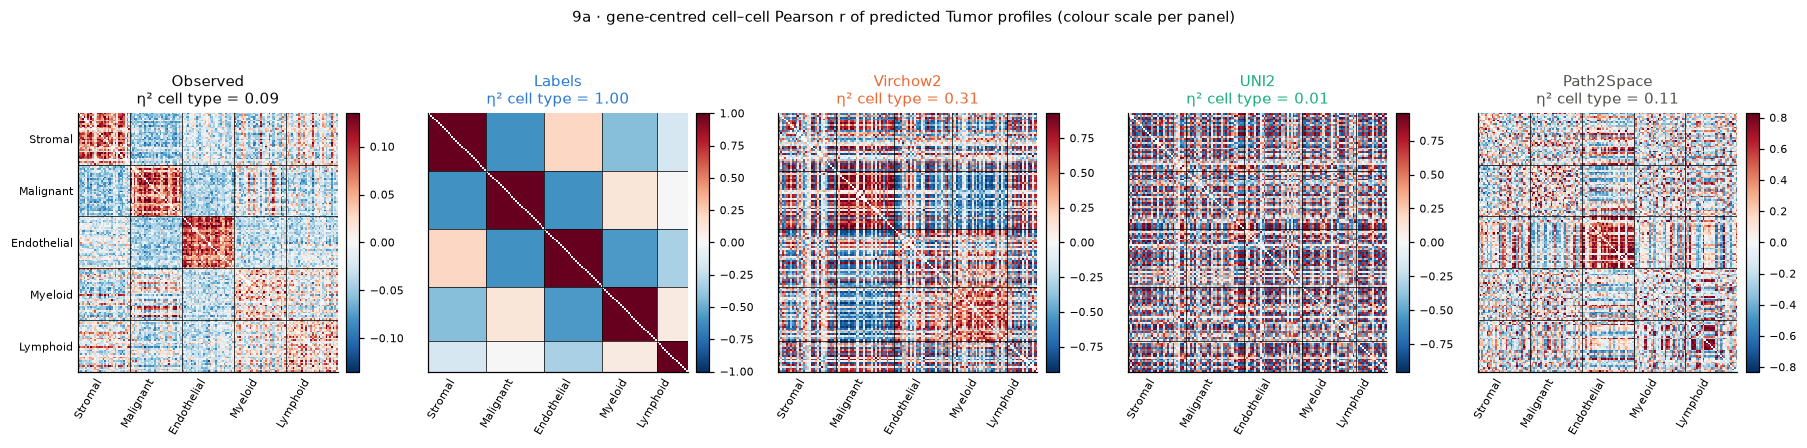

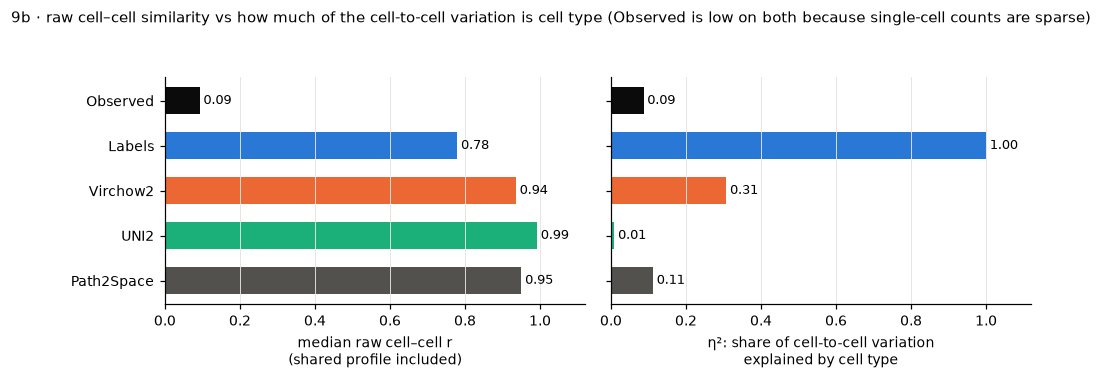

In [15]:
# --- 9a: gene-centred cell-cell correlation, cells ordered by type
fig, axes = plt.subplots(1, len(CC), figsize=(3.3 * len(CC), 3.9))
for ax, (name, d) in zip(axes, CC.items()):
    C = d["C"].copy(); np.fill_diagonal(C, np.nan)
    vmax = np.nanquantile(np.abs(C), 0.99)
    im = ax.imshow(C, cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
    bounds = np.cumsum([(d["ct"] == c).sum() for c in CORR_TYPES])
    for b in bounds[:-1]:
        ax.axhline(b - 0.5, color="#0b0b0b", lw=0.5); ax.axvline(b - 0.5, color="#0b0b0b", lw=0.5)
    mids = bounds - np.diff(np.r_[0, bounds]) / 2 - 0.5
    ax.set_xticks(mids); ax.set_xticklabels(CORR_TYPES, rotation=60, ha="right", fontsize=7.5)
    ax.set_yticks(mids); ax.set_yticklabels(CORR_TYPES if ax is axes[0] else [], fontsize=7.5)
    ax.tick_params(length=0)
    ax.set_title(f"{CC_NAME[name]}\nη² cell type = {d['eta2']:.2f}", fontsize=9.5, color=CC_COLOR[name])
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, shrink=0.8)
    cb.ax.tick_params(labelsize=7)
fig.suptitle("9a · gene-centred cell–cell Pearson r of predicted Tumor profiles "
             "(colour scale per panel)", y=1.02, fontsize=10)
plt.tight_layout()
save(fig, "fig9a_cell_cell_correlation")
plt.show()

# --- 9b: raw similarity vs how much of the cell-to-cell variation is cell type
names = list(CC)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, key, xl in [(axes[0], "raw_r", "median raw cell–cell r\n(shared profile included)"),
                    (axes[1], "eta2", "η²: share of cell-to-cell variation\nexplained by cell type")]:
    vals = [CC[n][key] for n in names]
    ax.barh(range(len(names)), vals, color=[CC_COLOR[n] for n in names], height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8.5)
    ax.set_xlim(0, 1.12); ax.set_xlabel(xl)
    ax.xaxis.grid(True, **GRID)
axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels([CC_NAME[n] for n in names])
axes[0].invert_yaxis()
fig.suptitle("9b · raw cell–cell similarity vs how much of the cell-to-cell variation is cell type "
             "(Observed is low on both because single-cell counts are sparse)", y=1.06, fontsize=10)
plt.tight_layout()
save(fig, "fig9b_similarity_vs_celltype")
plt.show()

## 10. How much does each input drive the prediction? (input-influence ablation)

§9 measured how predicted cells *differ*, but the cells there differed in several ways at once.
Here each trained model is queried directly, with no retraining.
`scripts/input_influence_ablation.py` decodes a **full factorial grid**: every cell type (all 7 the
models know) × every context. It then splits the variance of the predicted log-expression with a
balanced two-way ANOVA (per gene, summed over genes):

**output variation = cell type + context + interaction**

| model | context = the second input | grid |
|---|---|---|
| Labels | the 5 domain one-hots | 7 × 5 |
| Virchow2 / UNI2, *Tumor donors* | 300 embeddings of non-Stromal Tumor cells from ROIs 3/6/8/9: the pool the counterfactual draws from | 7 × 300 |
| Virchow2 / UNI2, *all tissues* | 60 embeddings from each of the 5 domains | 7 × 300 |

Library size is factored out (CPM), so these two inputs are the only things that can move the
output. The same donor cells are used for every model and seed. Before the grid was decoded,
every loaded model was checked to reproduce its cached counterfactual prediction (max |ΔCPM| ≤
1e-3). The shared profile, which is identical for every grid point, is left out of the split.
Mean ± s.d. over 3 seeds.

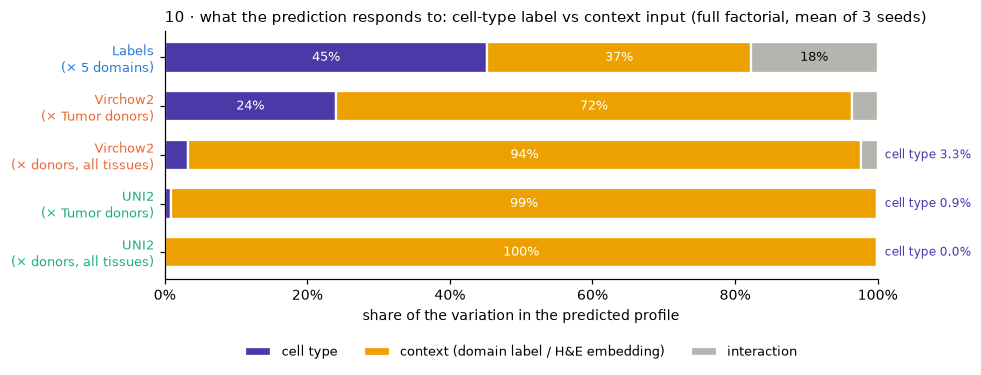

type mean  type std  context mean  context std  \
model    panel                                                               
Labels   domains                 45.3       0.3          36.9          0.2   
UNI2     donor_all_tissues        0.0       0.0          99.9          0.0   
         donor_tumor_rois         0.9       0.5          99.0          0.6   
Virchow2 donor_all_tissues        3.3       0.4          94.3          0.5   
         donor_tumor_rois        24.0       1.3          72.4          2.0   

                            interaction mean  interaction std  
model    panel                                                 
Labels   domains                        17.8              0.2  
UNI2     donor_all_tissues               0.0              0.0  
         donor_tumor_rois                0.1              0.1  
Virchow2 donor_all_tissues               2.4              0.2  
         donor_tumor_rois                3.6              0.6

In [16]:
INFL = pd.read_csv(os.path.join(PRED_DIR, "influence", "anova.csv"))
INFL_ROWS = [("Labels", "domains", "Labels\n(× 5 domains)"),
             ("Virchow2", "donor_tumor_rois", "Virchow2\n(× Tumor donors)"),
             ("Virchow2", "donor_all_tissues", "Virchow2\n(× donors, all tissues)"),
             ("UNI2", "donor_tumor_rois", "UNI2\n(× Tumor donors)"),
             ("UNI2", "donor_all_tissues", "UNI2\n(× donors, all tissues)")]
PARTS = [("frac_type", "cell type", "#4a3aa7"),
         ("frac_context", "context (domain label / H&E embedding)", "#eda100"),
         ("frac_interaction", "interaction", "#b5b4ae")]
summ = INFL.groupby(["model", "panel"])[[p for p, _, _ in PARTS]].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (m, panel, label) in enumerate(INFL_ROWS):
    left = 0.0
    for p, name, c in PARTS:
        v = summ.loc[(m, panel), (p, "mean")]
        ax.barh(i, v, left=left, color=c, height=0.62, edgecolor="white", lw=1.5,
                label=name if i == 0 else None)
        if v >= 0.06:
            ax.text(left + v / 2, i, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if p != "frac_interaction" else "#0b0b0b")
        left += v
    t = summ.loc[(m, panel), ("frac_type", "mean")]
    if t < 0.06:
        ax.text(1.01, i, f"cell type {100 * t:.1f}%", va="center", fontsize=8, color="#4a3aa7")
ax.set_yticks(range(len(INFL_ROWS))); ax.set_yticklabels([r[2] for r in INFL_ROWS], fontsize=8.5)
for t, (m, _, _) in zip(ax.get_yticklabels(), INFL_ROWS):
    t.set_color(FAMILY_COLOR[{"Labels": "labels", "Virchow2": "virchow2", "UNI2": "uni2"}[m]])
ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("share of the variation in the predicted profile")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{100 * x:.0f}%"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8.5)
ax.set_title("10 · what the prediction responds to: cell-type label vs context input "
             "(full factorial, mean of 3 seeds)", loc="left", fontsize=10)
plt.tight_layout()
save(fig, "fig10_input_influence")
plt.show()

tbl = summ.copy()
tbl.columns = [f"{a.replace('frac_', '')} {b}" for a, b in tbl.columns]
(100 * tbl).round(1)

**Reading §10 (2026-10-08).**

- **Labels**: cell type 45%, domain 37%, interaction 18%. Both inputs matter, and the interaction
  means a domain effect can depend on the cell type.
- **Virchow2, Tumor donors** (the counterfactual setting): cell type 24%, donor 72%. *Which* Tumor
  cell lends its tile moves the prediction about 3× more than the cell type does. Across all
  tissues the embedding takes 94% and cell type only 3%.
- **UNI2**: cell type ≈ 1% with Tumor donors and 0.0% across tissues. **The trained UNI2 decoder
  effectively ignores the cell-type input**; its output is a function of the image vector alone.
  That is consistent with §9 (η² ≈ 0.01) and with UNI2 being the weakest row in the OOD
  benchmark.

A likely mechanism, not tested here: the first decoder layer is a plain `Linear` over
`[7 one-hot dims | 1,536–2,560 standardised embedding dims]`. The embedding block is hundreds of
times wider, so the optimiser can fit the training cells through it, and the one-hot (whose cell
type the tile partly encodes anyway) adds little.

## 11. What the data looks like: H&E, ROIs and tissue domains

Descriptive figures, no model output. Source: `OVCA_with_embeddings.zarr` (H&E, the 36 ROI
circles, per-cell `domain` and `cell_type` from the 10x / SpatialFusion annotation). Needs
`spatialdata`, so run this section on `lazyslide-env`, not `cellina_edge`.

- **11a**: the whole slide with all 36 ROIs (150 µm radius) coloured by their domain; the
  held-out Tumor ROIs 3/6/8/9 are dashed. Right: every annotated cell coloured by domain.
- **11b**: one ROI per domain at full resolution: H&E on top, cell types below.

Cell centroids (µm) are mapped to H&E pixels through the inverse of the H&E→Xenium affine; this
matches the `x_he`/`y_he` stored in `roi_cells` exactly. The ×16 whole-slide thumbnail takes about
a minute to read once and is cached next to the zarr.

In [ ]:
import spatialdata as sd
from spatialdata.transformations import get_transformation
from matplotlib.patches import Circle
import matplotlib.patheffects as pe

ZARR = "/scratch/spiljak/wsi_ood_datasets/OVCA_with_embeddings.zarr"
THUMB = "/scratch/spiljak/wsi_ood_datasets/OVCA_he_thumb_ds16.npy"   # cached x16 thumbnail
DS = 16
XENIUM_UM_PER_PX = 0.2125
HOLDOUT_ROIS = [3, 6, 8, 9]

sdata = sd.read_zarr(ZARR)
he = sdata.images["he"]
rois = sdata.shapes["roi_polygons"].drop(columns="geometry").set_index("roi_id")
HE_UM_PER_PX = (rois.radius_um / rois.radius_he_px).iloc[0]

# cell centroids (µm) -> Xenium px (global CS) -> H&E px via the inverse of the H&E affine
cells = sdata.tables["table"].obs[["cell_type", "domain"]].copy()
xy_um = sdata.tables["table"].obsm["spatial"]
A = get_transformation(he).to_affine_matrix(input_axes=("x", "y"), output_axes=("x", "y"))
xy_he = np.c_[xy_um / XENIUM_UM_PER_PX, np.ones(len(xy_um))] @ np.linalg.inv(A).T
cells["x"], cells["y"] = xy_he[:, 0], xy_he[:, 1]
_r = sdata.tables["roi_cells"].obs.set_index("cell_id")
assert np.allclose(cells.loc[_r.index, ["x", "y"]].to_numpy(), _r[["x_he", "y_he"]].to_numpy(), atol=0.5)

if os.path.exists(THUMB):
    thumb = np.load(THUMB)
else:
    thumb = he.data[:, ::DS, ::DS].compute().transpose(1, 2, 0)
    np.save(THUMB, thumb)

DOMAIN_COLOR = {"Tumor": "#c0392b", "Smooth muscle": "#2a78d6", "Necrosis": "#52514e",
                "Fallopian tube": "#1baf7a", "Ovary": "#eda100"}
CT_COLOR = {"Malignant": "#c0392b", "Stromal": "#2a78d6", "Myeloid": "#eda100", "Endothelial": "#1baf7a",
            "Lymphoid": "#8e44ad", "Epithelial": "#e377c2", "Pericytes": "#17becf"}
HALO = [pe.withStroke(linewidth=2.5, foreground="white")]


def scalebar(ax, um, label, loc=(0.05, 0.05)):
    """Scale bar of `um` microns at axes fraction `loc` (axes use H&E px, y inverted)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    L = um / HE_UM_PER_PX
    bx, by = x0 + loc[0] * (x1 - x0), y0 + loc[1] * (y1 - y0)
    ax.plot([bx, bx + L], [by, by], color="black", lw=3, solid_capstyle="butt", path_effects=HALO)
    ax.text(bx + L / 2, by - 0.015 * (y0 - y1), label, ha="center", va="bottom", fontsize=8,
            path_effects=HALO)


# --- 11a: whole slide
H, W = thumb.shape[:2]
fig, axes = plt.subplots(1, 2, figsize=(10, 7.4))
for ax in axes:
    ax.imshow(thumb, extent=(0, W * DS, H * DS, 0), interpolation="lanczos")
    ax.set_axis_off()
ax = axes[0]
for rid, row in rois.iterrows():
    hold = rid in HOLDOUT_ROIS
    ax.add_patch(Circle((row.center_x_he, row.center_y_he), row.radius_he_px, fill=False,
                        ec=DOMAIN_COLOR[row.roi_domain], lw=2.2 if hold else 1.2, ls="--" if hold else "-"))
    ax.text(row.center_x_he + 1.15 * row.radius_he_px, row.center_y_he, str(rid), fontsize=6.5,
            va="center", fontweight="bold" if hold else "normal", path_effects=HALO)
ax.set_title("H&E with the 36 ROIs (150 µm radius)")
ax.legend(handles=[Line2D([], [], color=c, lw=2, label=d) for d, c in DOMAIN_COLOR.items()]
          + [Line2D([], [], color="black", lw=2, ls="--", label="held-out ROIs 3/6/8/9")],
          loc="lower left", fontsize=7.5, frameon=True, framealpha=0.9)
ax = axes[1]
ax.imshow(np.full_like(thumb, 255), extent=(0, W * DS, H * DS, 0), alpha=0.45)   # fade the H&E
sub = cells[cells.domain.isin(list(DOMAIN_COLOR))].sample(frac=0.5, random_state=0)
ax.scatter(sub.x, sub.y, c=sub.domain.map(DOMAIN_COLOR), s=0.15, lw=0, rasterized=True)
ax.set_title("Annotated tissue domains (one dot per cell)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=c, ms=6, label=d) for d, c in DOMAIN_COLOR.items()],
          loc="lower left", fontsize=7.5, frameon=True, framealpha=0.9)
for ax in axes:
    ax.set_xlim(0, W * DS); ax.set_ylim(H * DS, 0)
    scalebar(ax, 2000, "2 mm", loc=(0.74, 0.955))
plt.tight_layout()
save(fig, "fig11a_he_overview")
plt.show()

# --- 11b: one ROI per domain, full resolution
GALLERY = [(6, "Tumor (held out)"), (1, "Tumor"), (16, "Smooth muscle"), (25, "Necrosis"),
           (28, "Fallopian tube"), (31, "Ovary")]
PAD = 1.25   # crop half-width, in ROI radii
fig, axes = plt.subplots(2, len(GALLERY), figsize=(2.6 * len(GALLERY), 5.6))
for j, (rid, title) in enumerate(GALLERY):
    row = rois.loc[rid]
    cx, cy, R = row.center_x_he, row.center_y_he, row.radius_he_px
    x0, x1, y0, y1 = int(cx - PAD * R), int(cx + PAD * R), int(cy - PAD * R), int(cy + PAD * R)
    crop = he.data[:, y0:y1, x0:x1].compute().transpose(1, 2, 0)
    c = cells[cells.x.between(x0, x1) & cells.y.between(y0, y1) & cells.cell_type.isin(list(CT_COLOR))]
    for i, ax in enumerate(axes[:, j]):
        ax.imshow(crop, extent=(x0, x1, y1, y0), alpha=1.0 if i == 0 else 0.55)
        ax.add_patch(Circle((cx, cy), R, fill=False, ec=DOMAIN_COLOR[row.roi_domain], lw=2,
                            ls="--" if rid in HOLDOUT_ROIS else "-"))
        if i == 1:
            ax.scatter(c.x, c.y, c=c.cell_type.map(CT_COLOR), s=4, lw=0)
        ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        if j == 0:
            scalebar(ax, 100, "100 µm", loc=(0.06, 0.05))
    axes[0, j].set_title(f"ROI {rid} · {title}", fontsize=9.5, color=DOMAIN_COLOR[row.roi_domain])
axes[0, 0].set_ylabel("H&E", fontsize=10)
axes[1, 0].set_ylabel("cell types", fontsize=10)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=col, ms=6, label=k) for k, col in CT_COLOR.items()],
           loc="lower center", ncol=7, fontsize=8.5, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout()
save(fig, "fig11b_roi_gallery")
plt.show()